# Proteomics QC: PR1 human heart, aortic stenosis / mitral regurgitation vs donor hearts

MaxQuant proteinGroups LFQ data from Nordmeyer et al. 2023 (PRIDE PXD023800): 75 left-ventricle biopsies (41 aortic stenosis, 17 mitral regurgitation, 17 control donor hearts).

The input Excel file is read straight from GitHub, so the notebook runs on any computer with internet access, with no local file path to set.

**Processing:** remove contaminants / reverse / only-by-site / fragments → zeros to NaN → log2 → keep proteins with ≥ 60 % non-zero values in at least one group → median normalization → Perseus-style imputation. Unusual samples and single-peptide proteins are flagged, not removed.

**How to run in VS Code:** open this file, click *Select Kernel* (top right) and pick the Python you installed the packages into, then *Run All* or Shift+Enter per cell. Plots appear below each cell.

Requires: `pip install pandas numpy matplotlib seaborn scipy openpyxl ipykernel`

## 0. Imports and settings

Libraries and all parameters you might want to change in one place.
MIN_VALID_FRACTION sets the missing-value filter: a protein is kept if at
least this fraction of samples has a value in at least one group.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# "raw.githubusercontent.com" serves the file itself; the normal github.com
# "blob" link serves a web page, which pandas can't read.
DATA_URL = ("https://raw.githubusercontent.com/LauraSeeling/"
            "PR1_Proteomics-/main/PR1_heart_valve_disease.xlsx")

FIRST_INTENSITY_COL = 15            # column P (0-based index 15)
FILTER_COLS = ["Potential contaminant", "Reverse", "Only identified by site"]
MIN_VALID_FRACTION = 0.60           # keep proteins with >= 60 % values in >= 1 group
MIN_PEPTIDES = 2                    # proteins with fewer razor+unique peptides are flagged
IMPUTE_DOWNSHIFT = 1.8              # Perseus imputation: shift down (in SD)
IMPUTE_WIDTH = 0.3                  # Perseus imputation: width (x SD)

# Order in which groups appear in plots (controls first, then disease)
GROUP_ORDER = ["control (donor heart)", "aortic stenosis", "mitral regurgitation"]
GROUP_COLORS = {
    "control (donor heart)": "#009E73",
    "aortic stenosis": "#D55E00",
    "mitral regurgitation": "#0072B2",
}

SEX_MARKERS = {"male": "o", "female": "^"}      # circle / triangle in PCA
SEX_COLORS = {"male": "#404040", "female": "#C8C8C8"}  # heatmap colour bar

sns.set_theme(style="whitegrid", context="notebook")

def show(fig):
    """Tidy the layout and show the figure."""
    fig.tight_layout()
    plt.show()

## 1. Load the data from GitHub

Reads two sheets: 'proteinGroups' (MaxQuant output, one row per protein
group) and 'samples' (group and sex for each LFQ intensity column). We need
the sample sheet to colour and sort samples by disease group.

In [2]:
raw = pd.read_excel(DATA_URL, sheet_name="proteinGroups")
samples = pd.read_excel(DATA_URL, sheet_name="samples")

print(f"Loaded {raw.shape[0]} protein groups x {raw.shape[1]} columns")
print(samples["group"].value_counts(), "\n")

Loaded 9782 protein groups x 90 columns
group
aortic stenosis          41
control (donor heart)    17
mitral regurgitation     17
Name: count, dtype: int64 



## 2. Remove contaminants, reverse hits, only-identified-by-site and fragments

MaxQuant marks problem proteins with '+':
  - Potential contaminant: keratins, trypsin, serum proteins etc.
  - Reverse: decoy hits used to estimate the false discovery rate
  - Only identified by site: identified only through a modified peptide,
    so there is little evidence for the protein itself

None of these are real biology, so every row with a '+' in any of the
three columns is dropped.

In addition, protein groups whose lead entry (the first of the
semicolon-separated FASTA headers) is a UniProt "Fragment" are removed,
because the sequence is incomplete and the quantification may not
represent the full-length protein. A row can fall into several
categories, so the counts overlap.

In [ ]:
is_flagged = raw[FILTER_COLS].eq("+").any(axis=1)
for col in FILTER_COLS:
    print(f"{col:<25} '+': {raw[col].eq('+').sum()}")

# Fragments: lead entry = first entry of the semicolon-separated FASTA headers
lead_header = raw["Fasta headers"].fillna("").str.split(";").str[0]
is_fragment = lead_header.str.contains("Fragment", case=False)
print(f"{'Fragment (lead entry)':<25}    : {is_fragment.sum()}")

is_flagged = is_flagged | is_fragment
df = raw.loc[~is_flagged].reset_index(drop=True)
print(f"\nRemoved {is_flagged.sum()} protein groups (categories overlap) "
      f"-> {len(df)} remain")

## 3. Extract the intensity matrix (column P onwards)

Splits the table into a numeric matrix (proteins x samples) with gene names
as row labels and short sample names as column labels. The sample
annotation is reordered to match the columns so colours line up.

In [4]:
intensity_cols = df.columns[FIRST_INTENSITY_COL:]
intens = df[intensity_cols].astype(float)
intens.index = df["Gene names"].fillna(df["Majority protein IDs"])
intens.columns = [c.replace("LFQ intensity ", "") for c in intensity_cols]

meta = samples.set_index("sample").loc[intens.columns]
sample_colors = meta["group"].map(GROUP_COLORS)

## 4. Replace 0 with NaN and log2 transform

MaxQuant writes 0 when a protein was not detected. That means "missing",
not "zero abundance", so it becomes NaN and is ignored in means, medians
and correlations. log2 makes the very skewed intensities roughly normal and
turns fold changes into differences (+1 = doubling).

In [5]:
intens_nan = intens.replace(0, np.nan)
log2_all = np.log2(intens_nan)

n_missing = intens_nan.isna().sum().sum()
print(f"Zeros replaced by NaN: {n_missing} "
      f"({100 * n_missing / intens_nan.size:.1f}% of all values)")

Zeros replaced by NaN: 326266 (52.0% of all values)


## 5. Average intensity vs number of zeros per protein (before filtering)

Shows whether missing values are random or linked to abundance. If
low-intensity proteins are missing more often, values are "missing not at
random" (below the detection limit), which matters for imputation later.
Points are coloured by the filter applied in the next step: blue = kept,
red = removed. Because the filter works per group, kept and removed
proteins overlap in the middle: a protein missing in many samples overall
is still kept if one group measured it reliably.

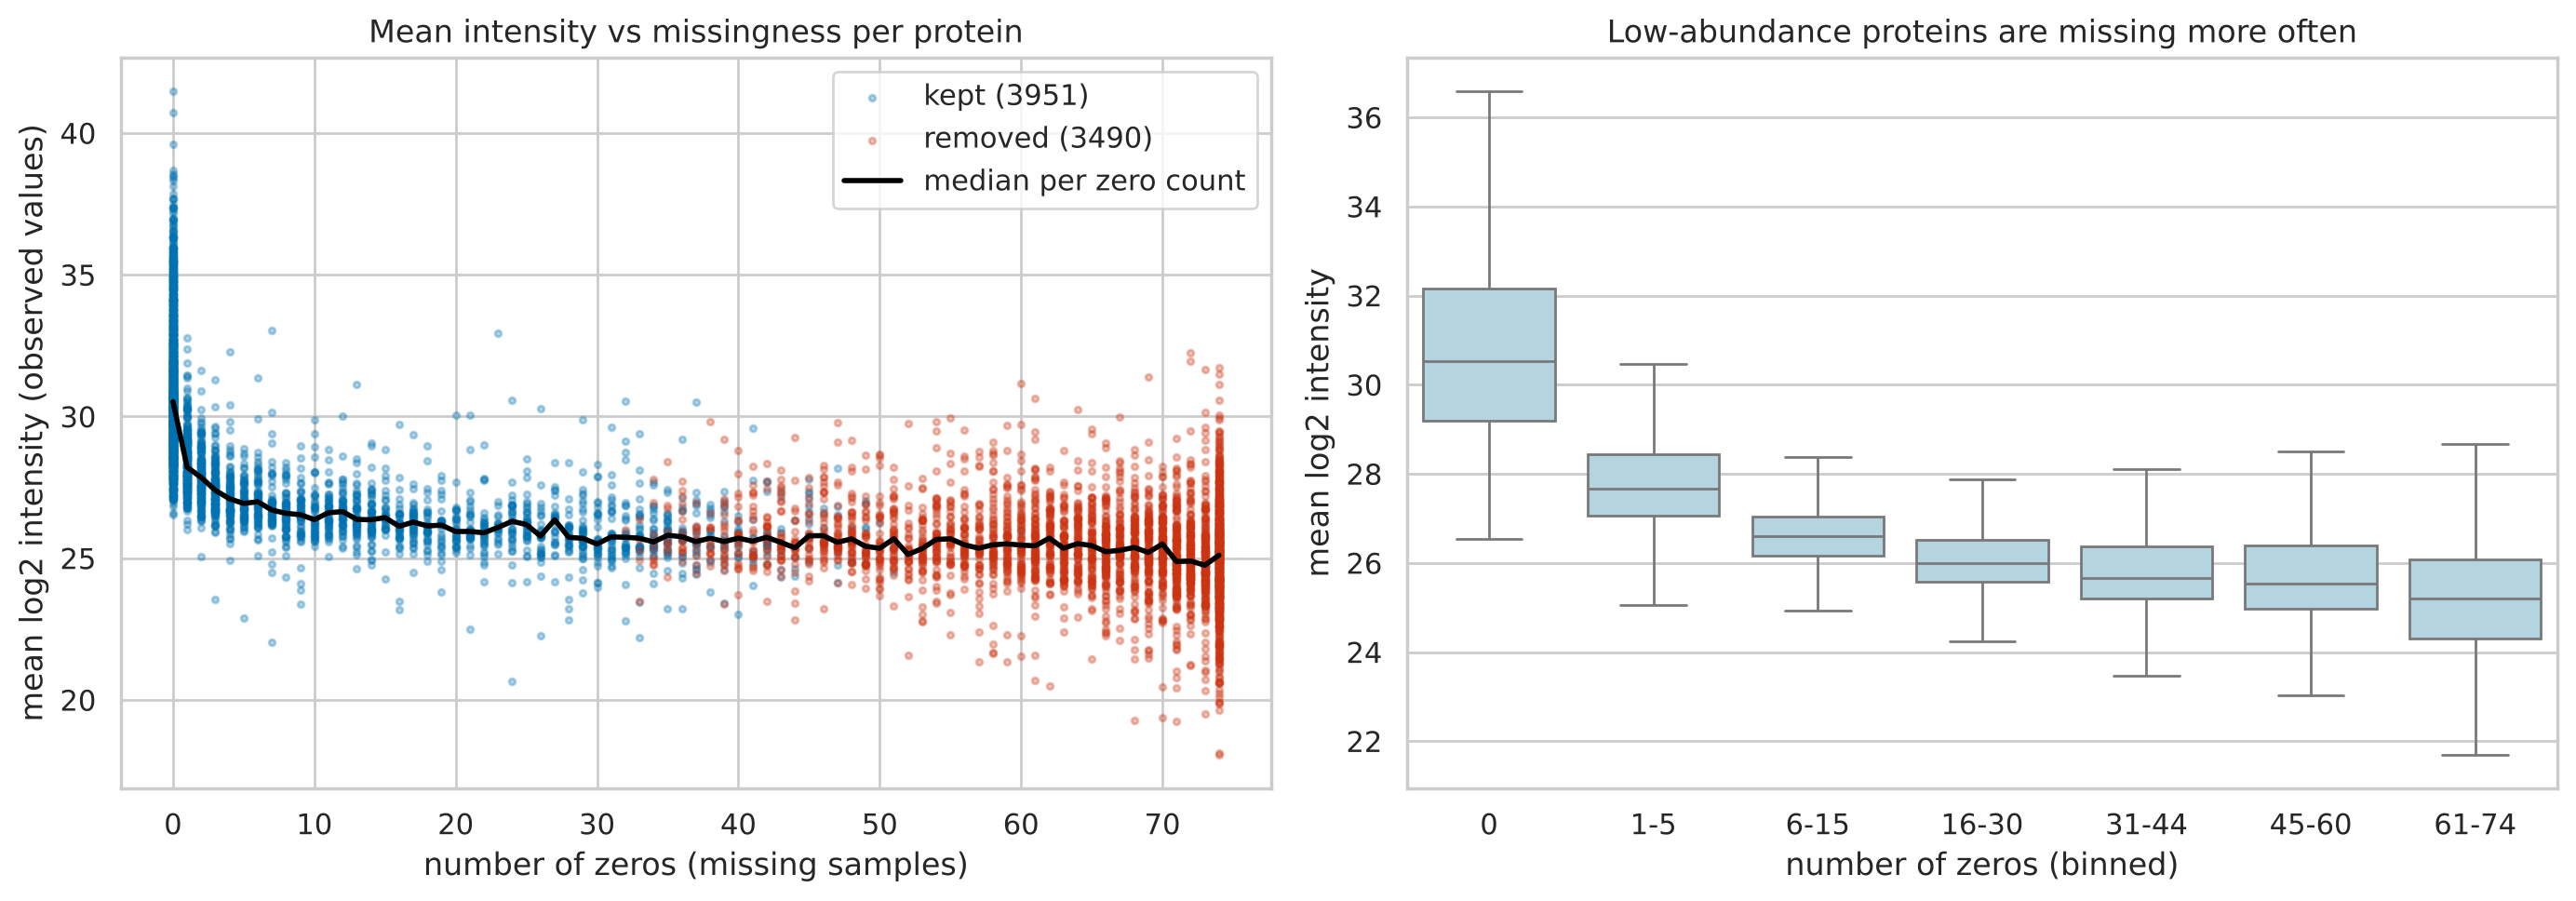

Spearman r (mean intensity vs zeros): -0.778


In [6]:
# Same rule as the filter in the next section, computed here for colouring
valid_frac_by_group = pd.DataFrame({
    g: intens_nan[meta.index[meta["group"] == g]].notna().mean(axis=1)
    for g in GROUP_ORDER})
passes_filter = (valid_frac_by_group >= MIN_VALID_FRACTION).any(axis=1)

protein_qc = pd.DataFrame({
    "mean_log2": log2_all.mean(axis=1),       # mean of observed values only
    "n_zeros": intens_nan.isna().sum(axis=1),
    "kept": passes_filter,
}).dropna(subset=["mean_log2"])               # drop never-observed proteins

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for kept, colour, label in [(True, "#0072B2", "kept"), (False, "#CC3311", "removed")]:
    sub = protein_qc[protein_qc["kept"] == kept]
    axes[0].scatter(sub["n_zeros"], sub["mean_log2"], s=6, alpha=0.3,
                    color=colour, label=f"{label} ({len(sub)})")
trend = protein_qc.groupby("n_zeros")["mean_log2"].median()
axes[0].plot(trend.index, trend.values, color="black", lw=2,
             label="median per zero count")
axes[0].set_xlabel("number of zeros (missing samples)")
axes[0].set_ylabel("mean log2 intensity (observed values)")
axes[0].set_title("Mean intensity vs missingness per protein")
axes[0].legend()

bins = pd.cut(protein_qc["n_zeros"], bins=[-1, 0, 5, 15, 30, 44, 60, 75],
              labels=["0", "1-5", "6-15", "16-30", "31-44", "45-60", "61-74"])
sns.boxplot(x=bins, y=protein_qc["mean_log2"], ax=axes[1],
            color="lightblue", showfliers=False)
axes[1].set_xlabel("number of zeros (binned)")
axes[1].set_ylabel("mean log2 intensity")
axes[1].set_title("Low-abundance proteins are missing more often")
show(fig)
print("Spearman r (mean intensity vs zeros):",
      round(protein_qc[["mean_log2", "n_zeros"]].corr(method="spearman").iloc[0, 1], 3))

## 6. Keep proteins with ≥ 60 % values in at least one group

Proteins measured in only a few samples give unreliable statistics and would need heavy imputation, so they are removed. The rule is applied **per group**: a protein is kept if at least 60 % of the samples in *at least one* group (control, AS or MR) have a value. A rule based on all 75 samples together would throw away proteins that are reliably measured in one group but mostly absent in the others, and those are exactly the proteins that may be biologically interesting (e.g. CRP, measured in most controls but few patients).

Everything below uses this filtered matrix ('log2').

In [7]:
keep = passes_filter.to_numpy()
log2 = log2_all.loc[keep]
intens_kept = intens_nan.loc[keep]
df_kept = df.loc[keep].reset_index(drop=True)
never_seen = intens_nan.isna().all(axis=1).sum()
print(f"Kept {keep.sum()} proteins, removed {(~keep).sum()} "
      f"({never_seen} of them were never detected in any sample)")
print(f"Missing values left: {100 * log2.isna().mean().mean():.1f}%")

# Proteins that pass only because of ONE group (fewer than 60 % values in
# the other groups): these are candidates for group-specific proteins.
group_specific = valid_frac_by_group.loc[keep]
only_one = (group_specific >= MIN_VALID_FRACTION).sum(axis=1) == 1
print(f"\nProteins that pass in only one group: {only_one.sum()}")
print((group_specific.loc[only_one] >= MIN_VALID_FRACTION).idxmax(axis=1)
      .value_counts().rename("passing group").to_string())

Kept 3951 proteins, removed 4414 (924 of them were never detected in any sample)
Missing values left: 10.4%

Proteins that pass in only one group: 302
control (donor heart)    139
mitral regurgitation      87
aortic stenosis           76


## 7. Flag proteins identified by only one peptide

A protein's intensity is calculated from its peptides. If only one peptide was found ('Razor + unique peptides' = 1), both the identification and the quantification rest on a single measurement, which makes them less reliable. These proteins are **kept but flagged**: the flag (`single_peptide`) lets results for these proteins be treated with caution later.

In [8]:
single_peptide = (df_kept["Razor + unique peptides"] < MIN_PEPTIDES).to_numpy()
protein_flags = pd.DataFrame({
    "Gene names": log2.index,
    "Razor + unique peptides": df_kept["Razor + unique peptides"].to_numpy(),
    "single_peptide": single_peptide,
    "missing_%": (100 * log2.isna().mean(axis=1)).round(1).to_numpy(),
    "median_log2": log2.median(axis=1).round(2).to_numpy(),
})
print(f"Proteins with < {MIN_PEPTIDES} razor+unique peptides: "
      f"{single_peptide.sum()} of {len(single_peptide)}")
print("Median % missing values: "
      f"{protein_flags.loc[single_peptide, 'missing_%'].median():.1f}% (single peptide) vs "
      f"{protein_flags.loc[~single_peptide, 'missing_%'].median():.1f}% (others)")
protein_flags.loc[single_peptide].sort_values("median_log2", ascending=False).head(10)

Proteins with < 2 razor+unique peptides: 91 of 3951
Median % missing values: 25.3% (single peptide) vs 1.3% (others)


,Gene names,Razor + unique peptides,single_peptide,missing_%,median_log2
1534,ATP5F1A,1,True,0.0,33.81
846,LDB3,1,True,0.0,31.20
2172,OGDH,1,True,28.0,31.02
709,UQCR11,1,True,0.0,30.90
1395,ATP2A2,1,True,0.0,29.86
731,NDUFA1,1,True,4.0,29.39
554,PDIA3,1,True,0.0,28.93
2090,TMSB10,1,True,4.0,28.79
2372,FLNC,1,True,14.7,28.66
358,IMMT,1,True,2.7,28.49


## 8. Before vs after transformation: distributions per sample

One box per sample. Raw intensities are squashed near zero by a few very
abundant proteins, so samples are hard to compare. After log2 the
distributions are symmetric and you can check that sample medians line up
(they should, because LFQ values are already normalised). A sample with a
shifted or much narrower box is worth a closer look.

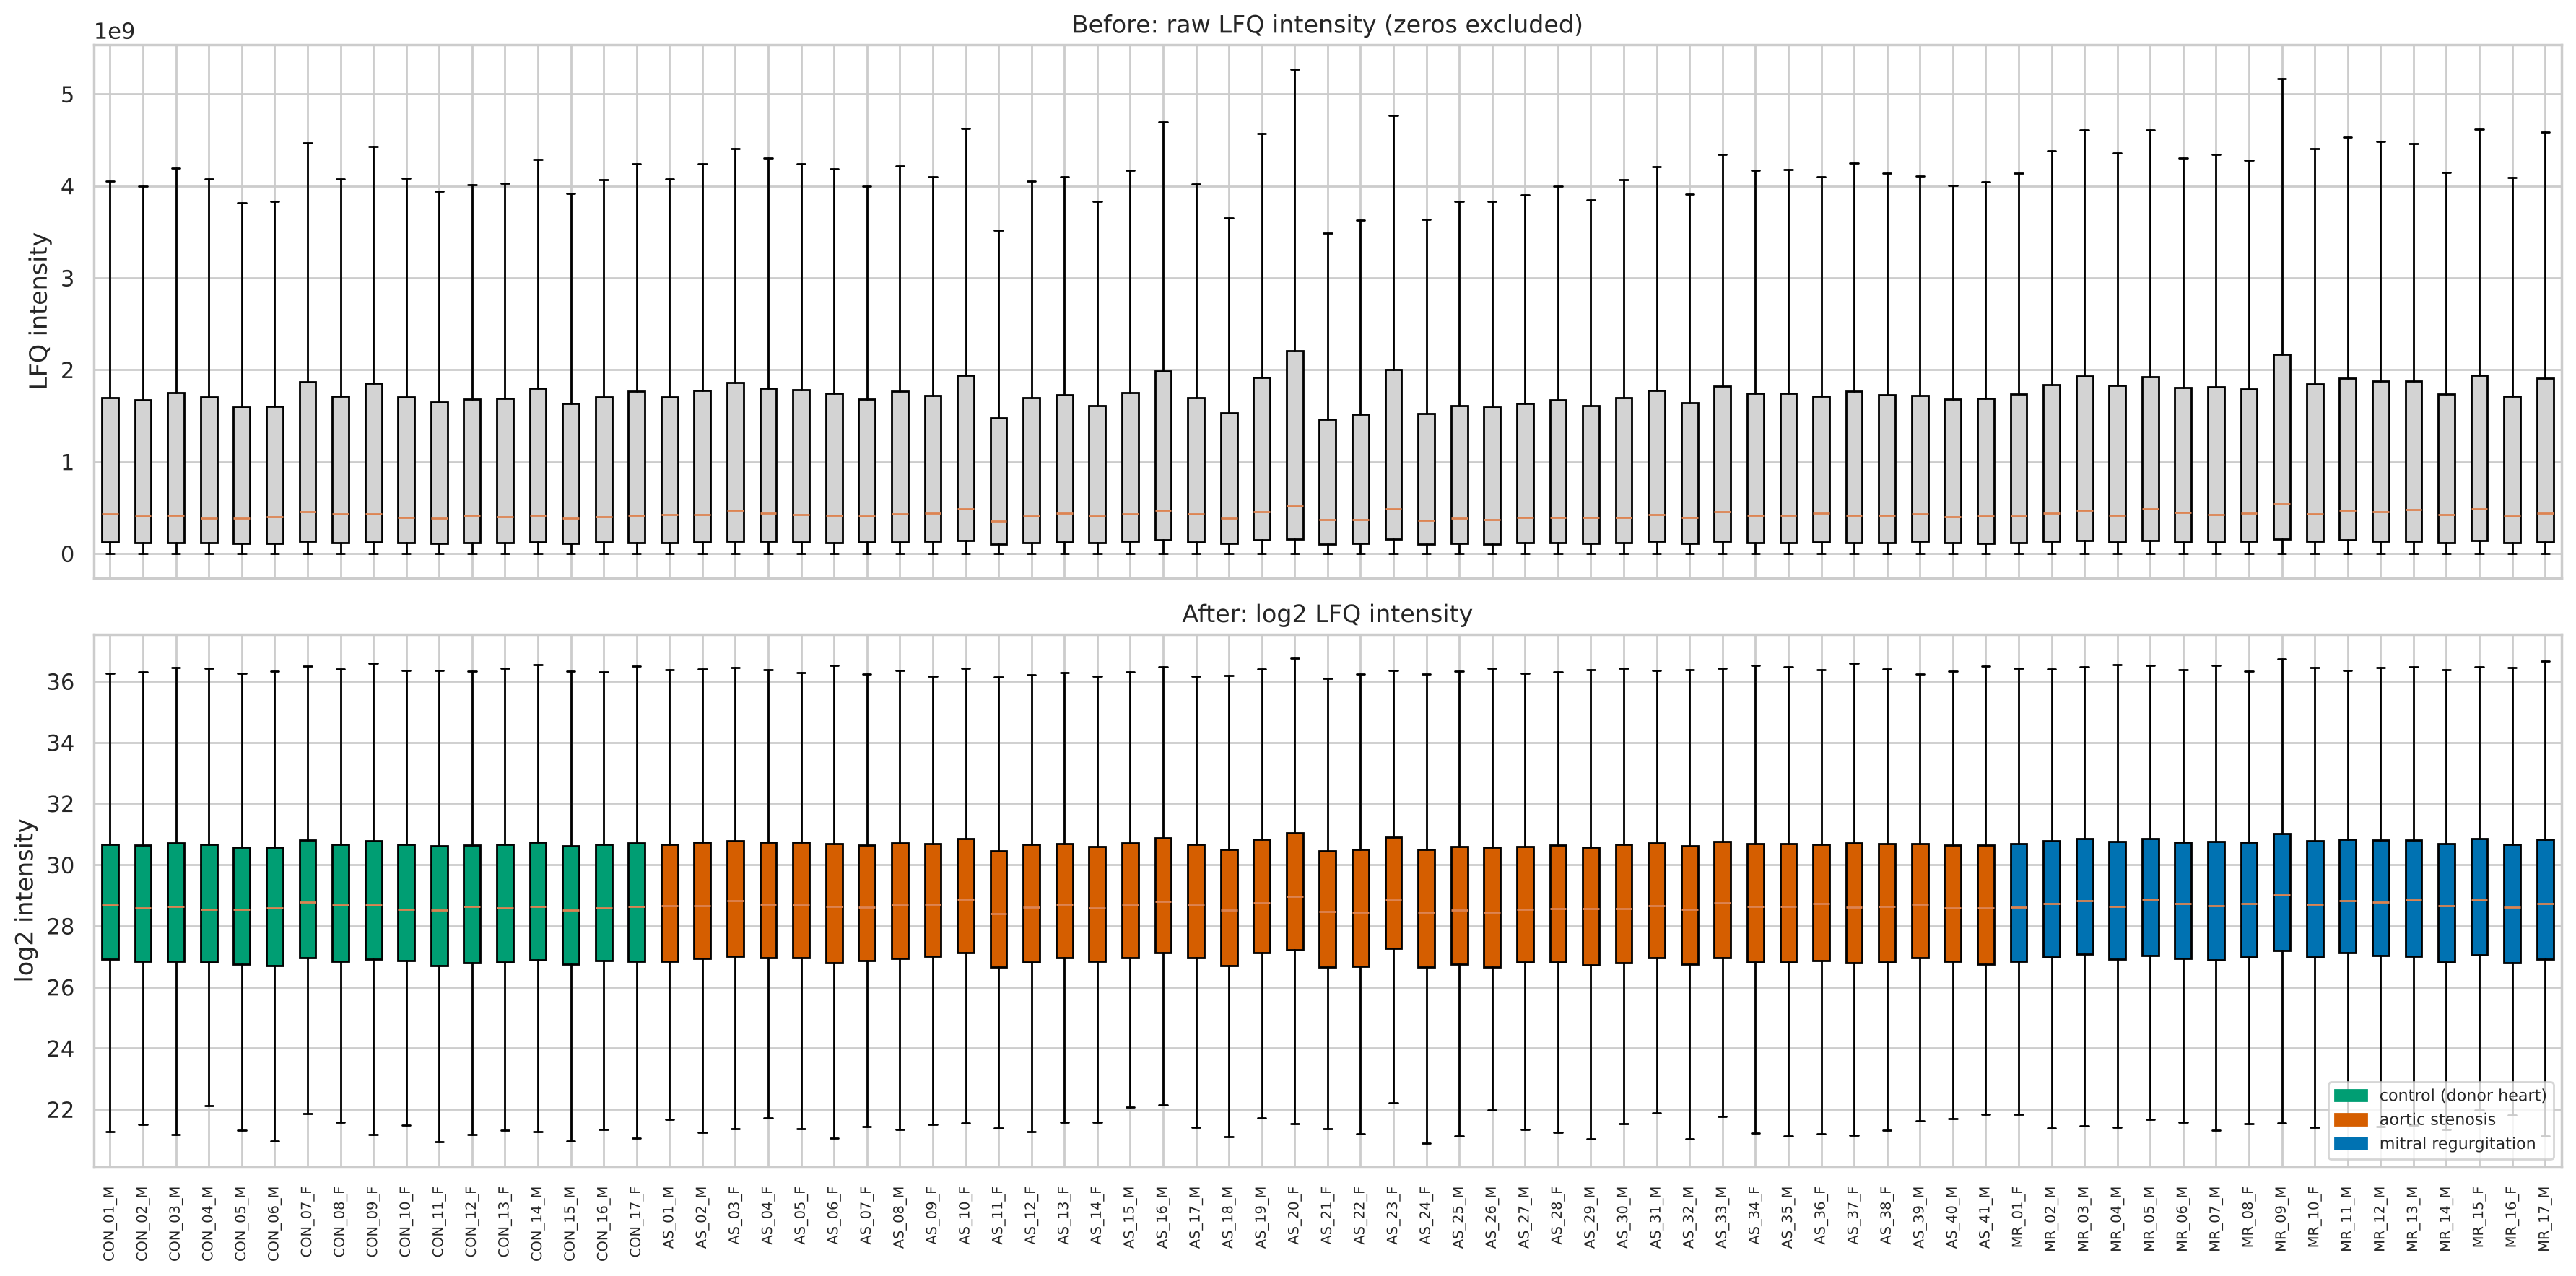

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(18, 9), sharex=True)
# samples sorted by group (control -> AS -> MR), then by name within group
order = meta.assign(g=pd.Categorical(meta["group"], GROUP_ORDER),
                    name=meta.index) \
            .sort_values(["g", "name"]).index

axes[0].boxplot([intens_kept[c].dropna() for c in order],
                showfliers=False, patch_artist=True,
                boxprops=dict(facecolor="lightgrey"))
axes[0].set_title("Before: raw LFQ intensity (zeros excluded)")
axes[0].set_ylabel("LFQ intensity")

bp = axes[1].boxplot([log2[c].dropna() for c in order],
                     showfliers=False, patch_artist=True)
for patch, s in zip(bp["boxes"], order):
    patch.set_facecolor(sample_colors[s])
axes[1].set_title("After: log2 LFQ intensity")
axes[1].set_ylabel("log2 intensity")
axes[1].set_xticks(range(1, len(order) + 1))
axes[1].set_xticklabels(order, rotation=90, fontsize=7)
handles = [plt.Rectangle((0, 0), 1, 1, color=GROUP_COLORS[g]) for g in GROUP_ORDER]
axes[1].legend(handles, GROUP_ORDER, loc="lower right", fontsize=8)
show(fig)

## 9. Before vs after: histogram of all values pooled

The same comparison with every value pooled: raw data is extremely
right-skewed, log2 data is close to a bell curve, which is what most
statistical tests (e.g. t-tests) assume.

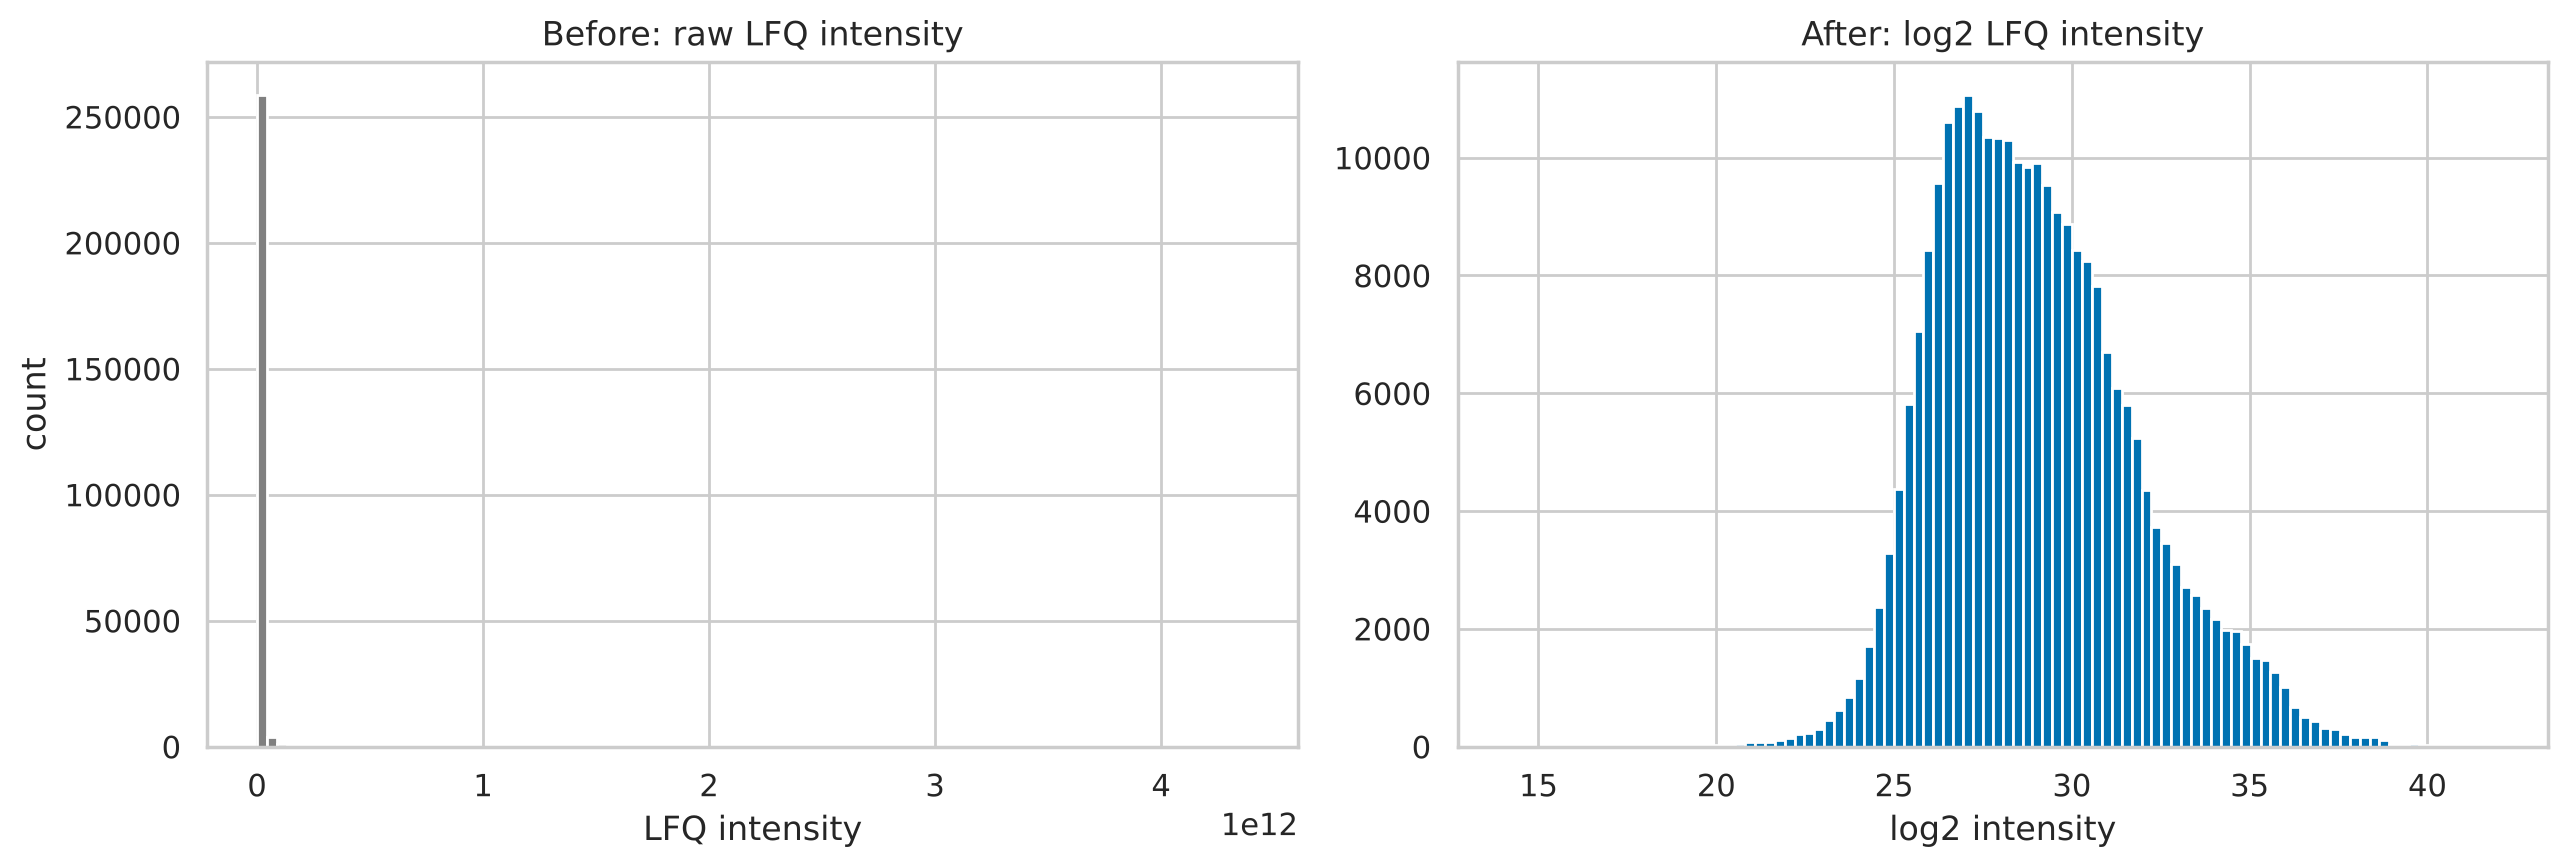

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(intens_kept.stack(), bins=100, color="grey")
axes[0].set_title("Before: raw LFQ intensity")
axes[0].set_xlabel("LFQ intensity")
axes[0].set_ylabel("count")

axes[1].hist(log2.stack(), bins=100, color="#0072B2")
axes[1].set_title("After: log2 LFQ intensity")
axes[1].set_xlabel("log2 intensity")
show(fig)

## 10. Median normalization

Small differences in how much protein was loaded or how well the LC-MS run
went shift ALL intensities of a sample up or down by the same amount. On
the log2 scale that is a constant offset, so we subtract each sample's
median and add back the overall median (to keep values on the usual
scale). Afterwards all sample medians are identical.

The median is computed only on proteins quantified in EVERY sample. If we
used all observed values, a sample that missed many low-abundance
proteins would get a higher median just because of what is missing, and
normalization would wrongly push it down.

Why not other normalizations?
- MaxQuant LFQ values are already normalized between samples (MaxLFQ), so
  only a gentle correction of any leftover offset is needed.
- Quantile normalization forces every sample to have the exact same
  distribution. With about 10 % missing values (mostly low-abundance proteins)
  samples have different numbers of proteins, so their distributions
  legitimately differ and quantile normalization would distort them. It
  can also erase real biology (e.g. a global shift in disease).
- Total-intensity (sum) normalization is dominated by a handful of very
  abundant proteins (myosin, titin, actin) and by which proteins happen to
  be missing, so one change in a big protein would rescale everything.
- Z-scoring each sample also equalizes the spread, which removes real
  differences in dynamic range and makes values hard to interpret.
- VSN / loess-type methods mainly fix intensity-dependent bias in
  complete data and are overkill when the boxplots show only small,
  constant offsets.
The median only assumes that most proteins do not change between samples,
is robust to outliers, and corrects exactly the problem we see.

Medians computed on 1807 proteins found in all samples
Correction per sample: -0.26 to +0.63 log2 units
Largest corrections (log2 units added):
AS_23_F    0.63
AS_22_F    0.30
AS_14_F    0.28
MR_09_M   -0.26
AS_21_F    0.25
dtype: float64


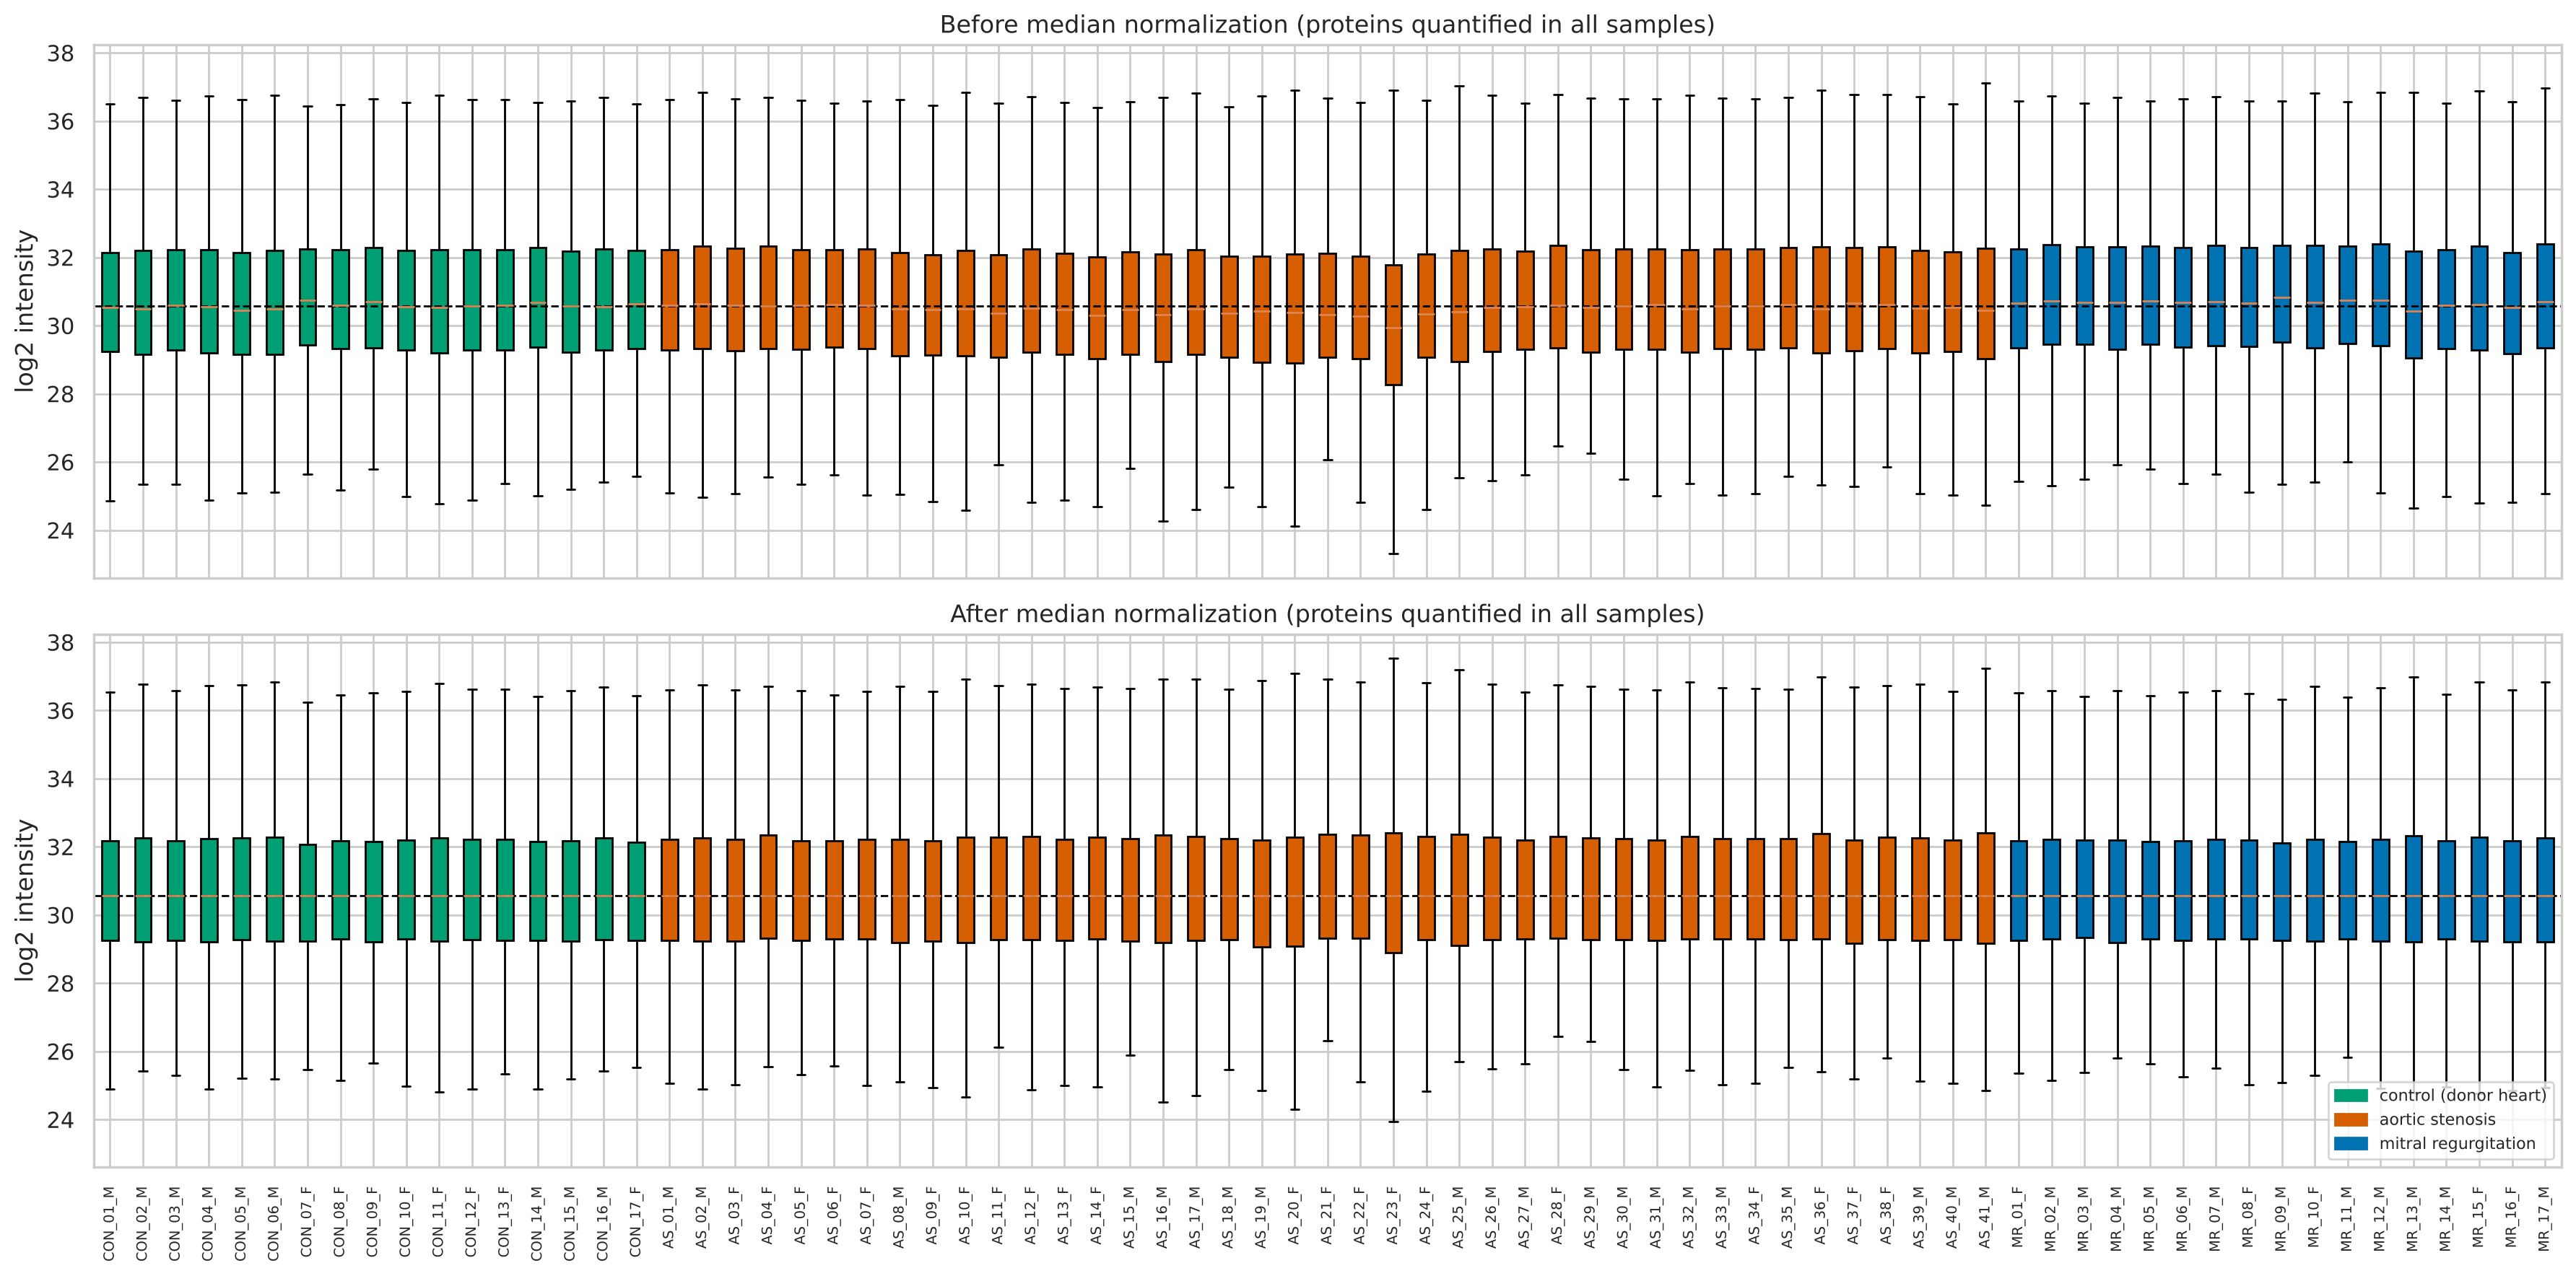

In [11]:
complete_rows = log2.notna().all(axis=1)
sample_medians = log2.loc[complete_rows].median()
log2_unnorm = log2.copy()
log2 = log2 - sample_medians + sample_medians.median()

correction = sample_medians.median() - sample_medians   # added to each sample
print(f"Medians computed on {complete_rows.sum()} proteins found in all samples")
print(f"Correction per sample: {correction.min():+.2f} to "
      f"{correction.max():+.2f} log2 units")
print("Largest corrections (log2 units added):")
print(correction.loc[correction.abs().sort_values(ascending=False).index]
      .head(5).round(2))

# Boxes show the proteins found in all samples, i.e. the values the
# medians were computed on, so after normalization the medians line up.
fig, axes = plt.subplots(2, 1, figsize=(18, 9), sharex=True, sharey=True)
for ax, data, title in [
        (axes[0], log2_unnorm.loc[complete_rows], "Before median normalization"),
        (axes[1], log2.loc[complete_rows], "After median normalization")]:
    bp = ax.boxplot([data[c] for c in order],
                    showfliers=False, patch_artist=True)
    for patch, s in zip(bp["boxes"], order):
        patch.set_facecolor(sample_colors[s])
    ax.axhline(data.median().median(), color="black", ls="--", lw=1)
    ax.set_title(f"{title} (proteins quantified in all samples)")
    ax.set_ylabel("log2 intensity")
axes[1].set_xticks(range(1, len(order) + 1))
axes[1].set_xticklabels(order, rotation=90, fontsize=7)
axes[1].legend(handles, GROUP_ORDER, loc="lower right", fontsize=8)
show(fig)

## 11. Proteins quantified per sample

How many proteins have a value in each sample, sorted by group. A sample
with far fewer proteins than the rest may have had less material or a poor
LC-MS run; a whole group with fewer proteins would be a batch effect.

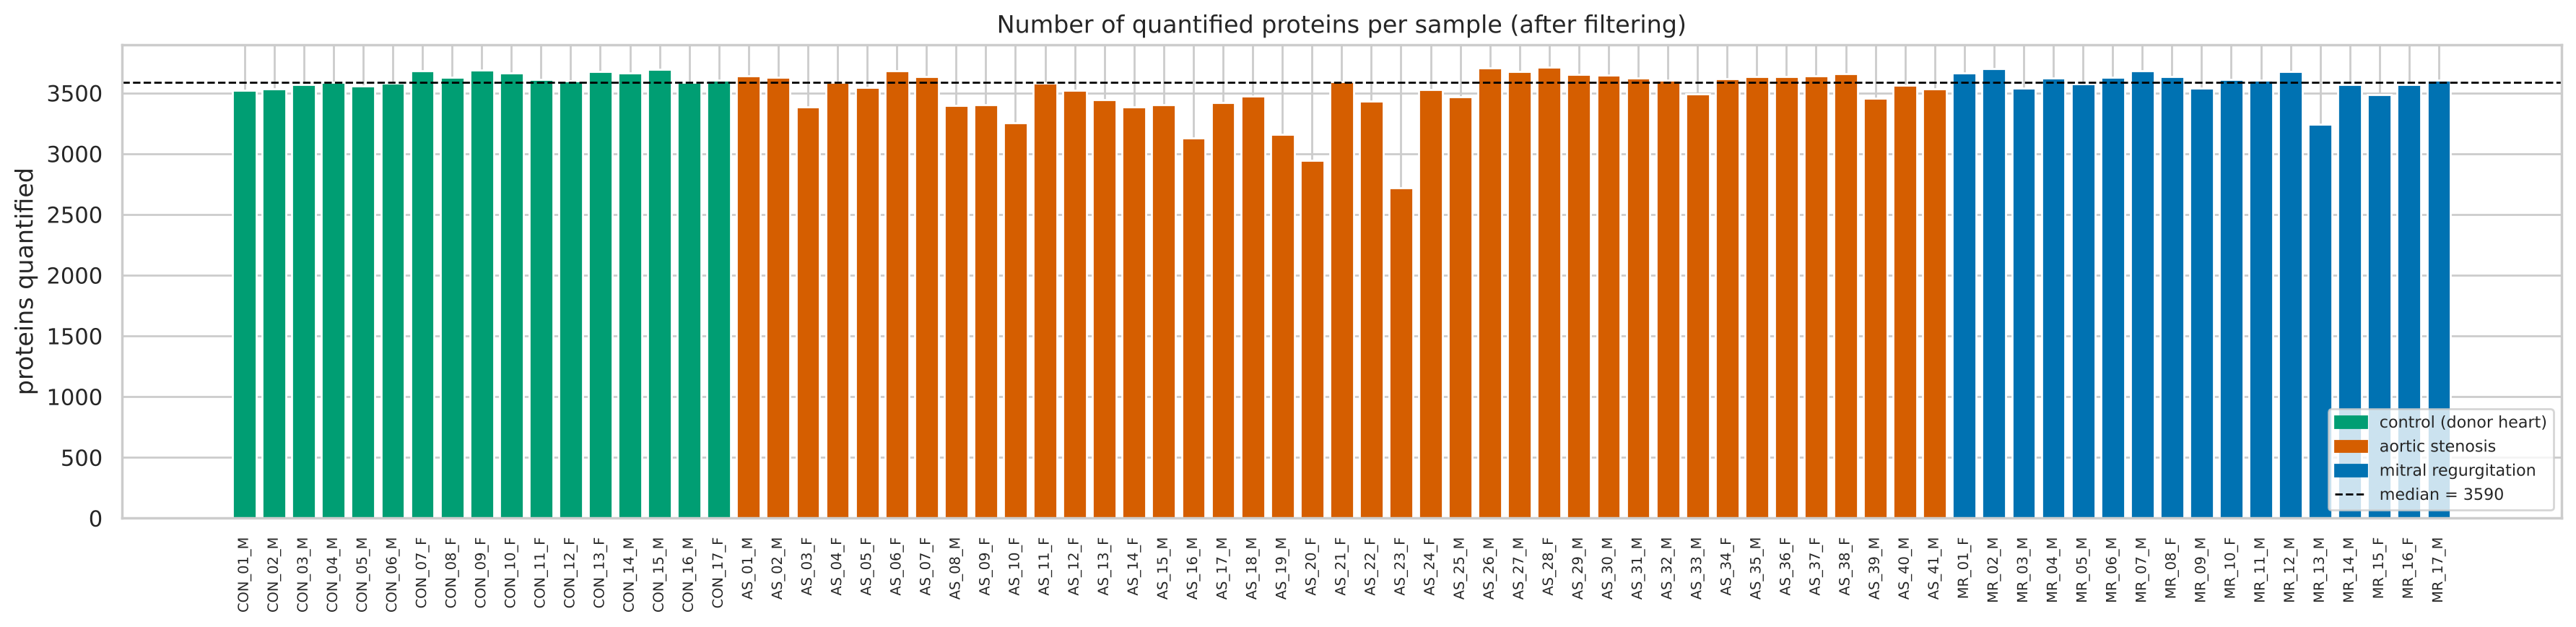

In [12]:
n_ident = log2.notna().sum()[order]
fig, ax = plt.subplots(figsize=(18, 4.5))
ax.bar(n_ident.index, n_ident.values, color=sample_colors[order].values)
med_line = ax.axhline(n_ident.median(), color="black", ls="--", lw=1)
ax.set_ylabel("proteins quantified")
ax.set_title("Number of quantified proteins per sample "
             "(after filtering)")
ax.tick_params(axis="x", rotation=90, labelsize=7)
ax.legend(handles + [med_line],
          GROUP_ORDER + [f"median = {n_ident.median():.0f}"],
          fontsize=8, loc="lower right")
show(fig)

## 12. Missing-value heatmap, samples sorted by group

Black = quantified, white = missing. Proteins are sorted from most to
least complete. If white blocks line up with one group, the missingness is
biological (the protein is really absent in that condition) or a batch
effect, rather than random.

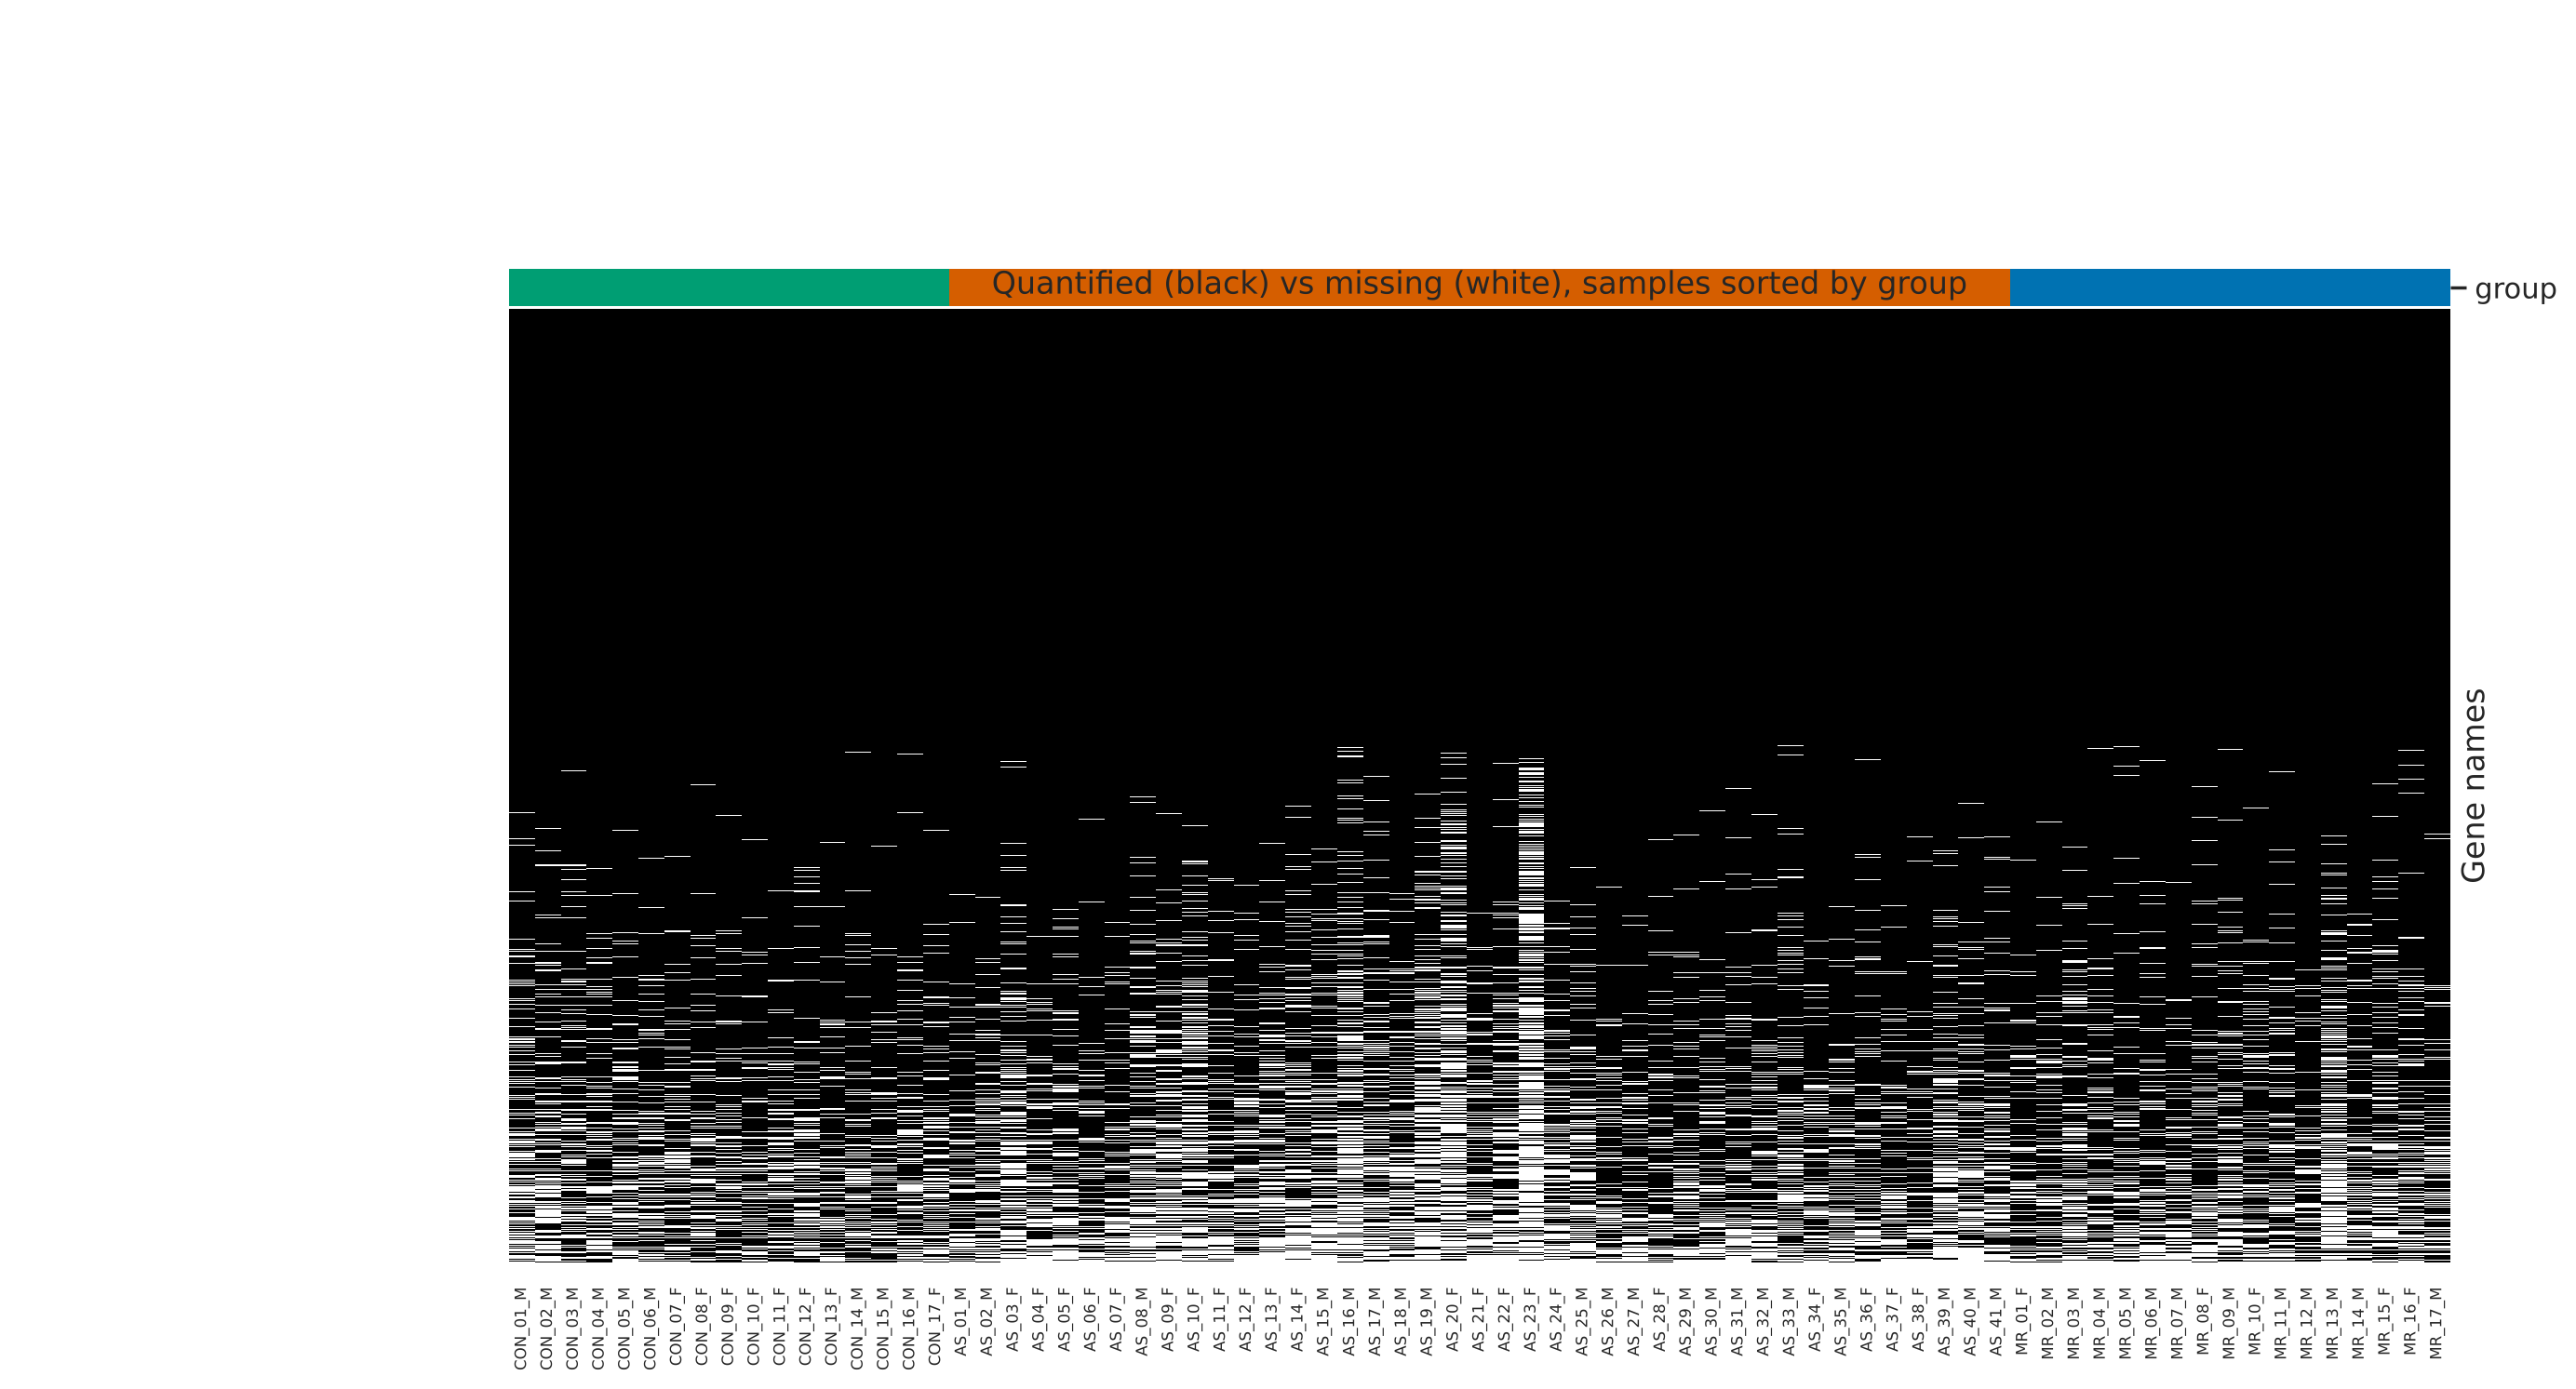

In [13]:
miss = log2[order].notna()
miss = miss.iloc[np.argsort(-miss.sum(axis=1).to_numpy(), kind="stable")]
g = sns.clustermap(miss.astype(int), row_cluster=False, col_cluster=False,
                   col_colors=sample_colors[order], cmap="Greys",
                   yticklabels=False, xticklabels=True, figsize=(14, 8),
                   cbar_pos=None)
g.ax_heatmap.set_title("Quantified (black) vs missing (white), samples sorted by group")
g.ax_heatmap.tick_params(axis="x", labelsize=6)
plt.show()

## 13. Sample-sample correlation, sorted by group

Pearson correlation between every pair of samples (using proteins seen in
both). Samples are ordered control -> aortic stenosis -> mitral
regurgitation with white lines between groups, so you can see whether
samples are more similar within their own group than to other groups.
A sample with low correlation to everything is a likely outlier.

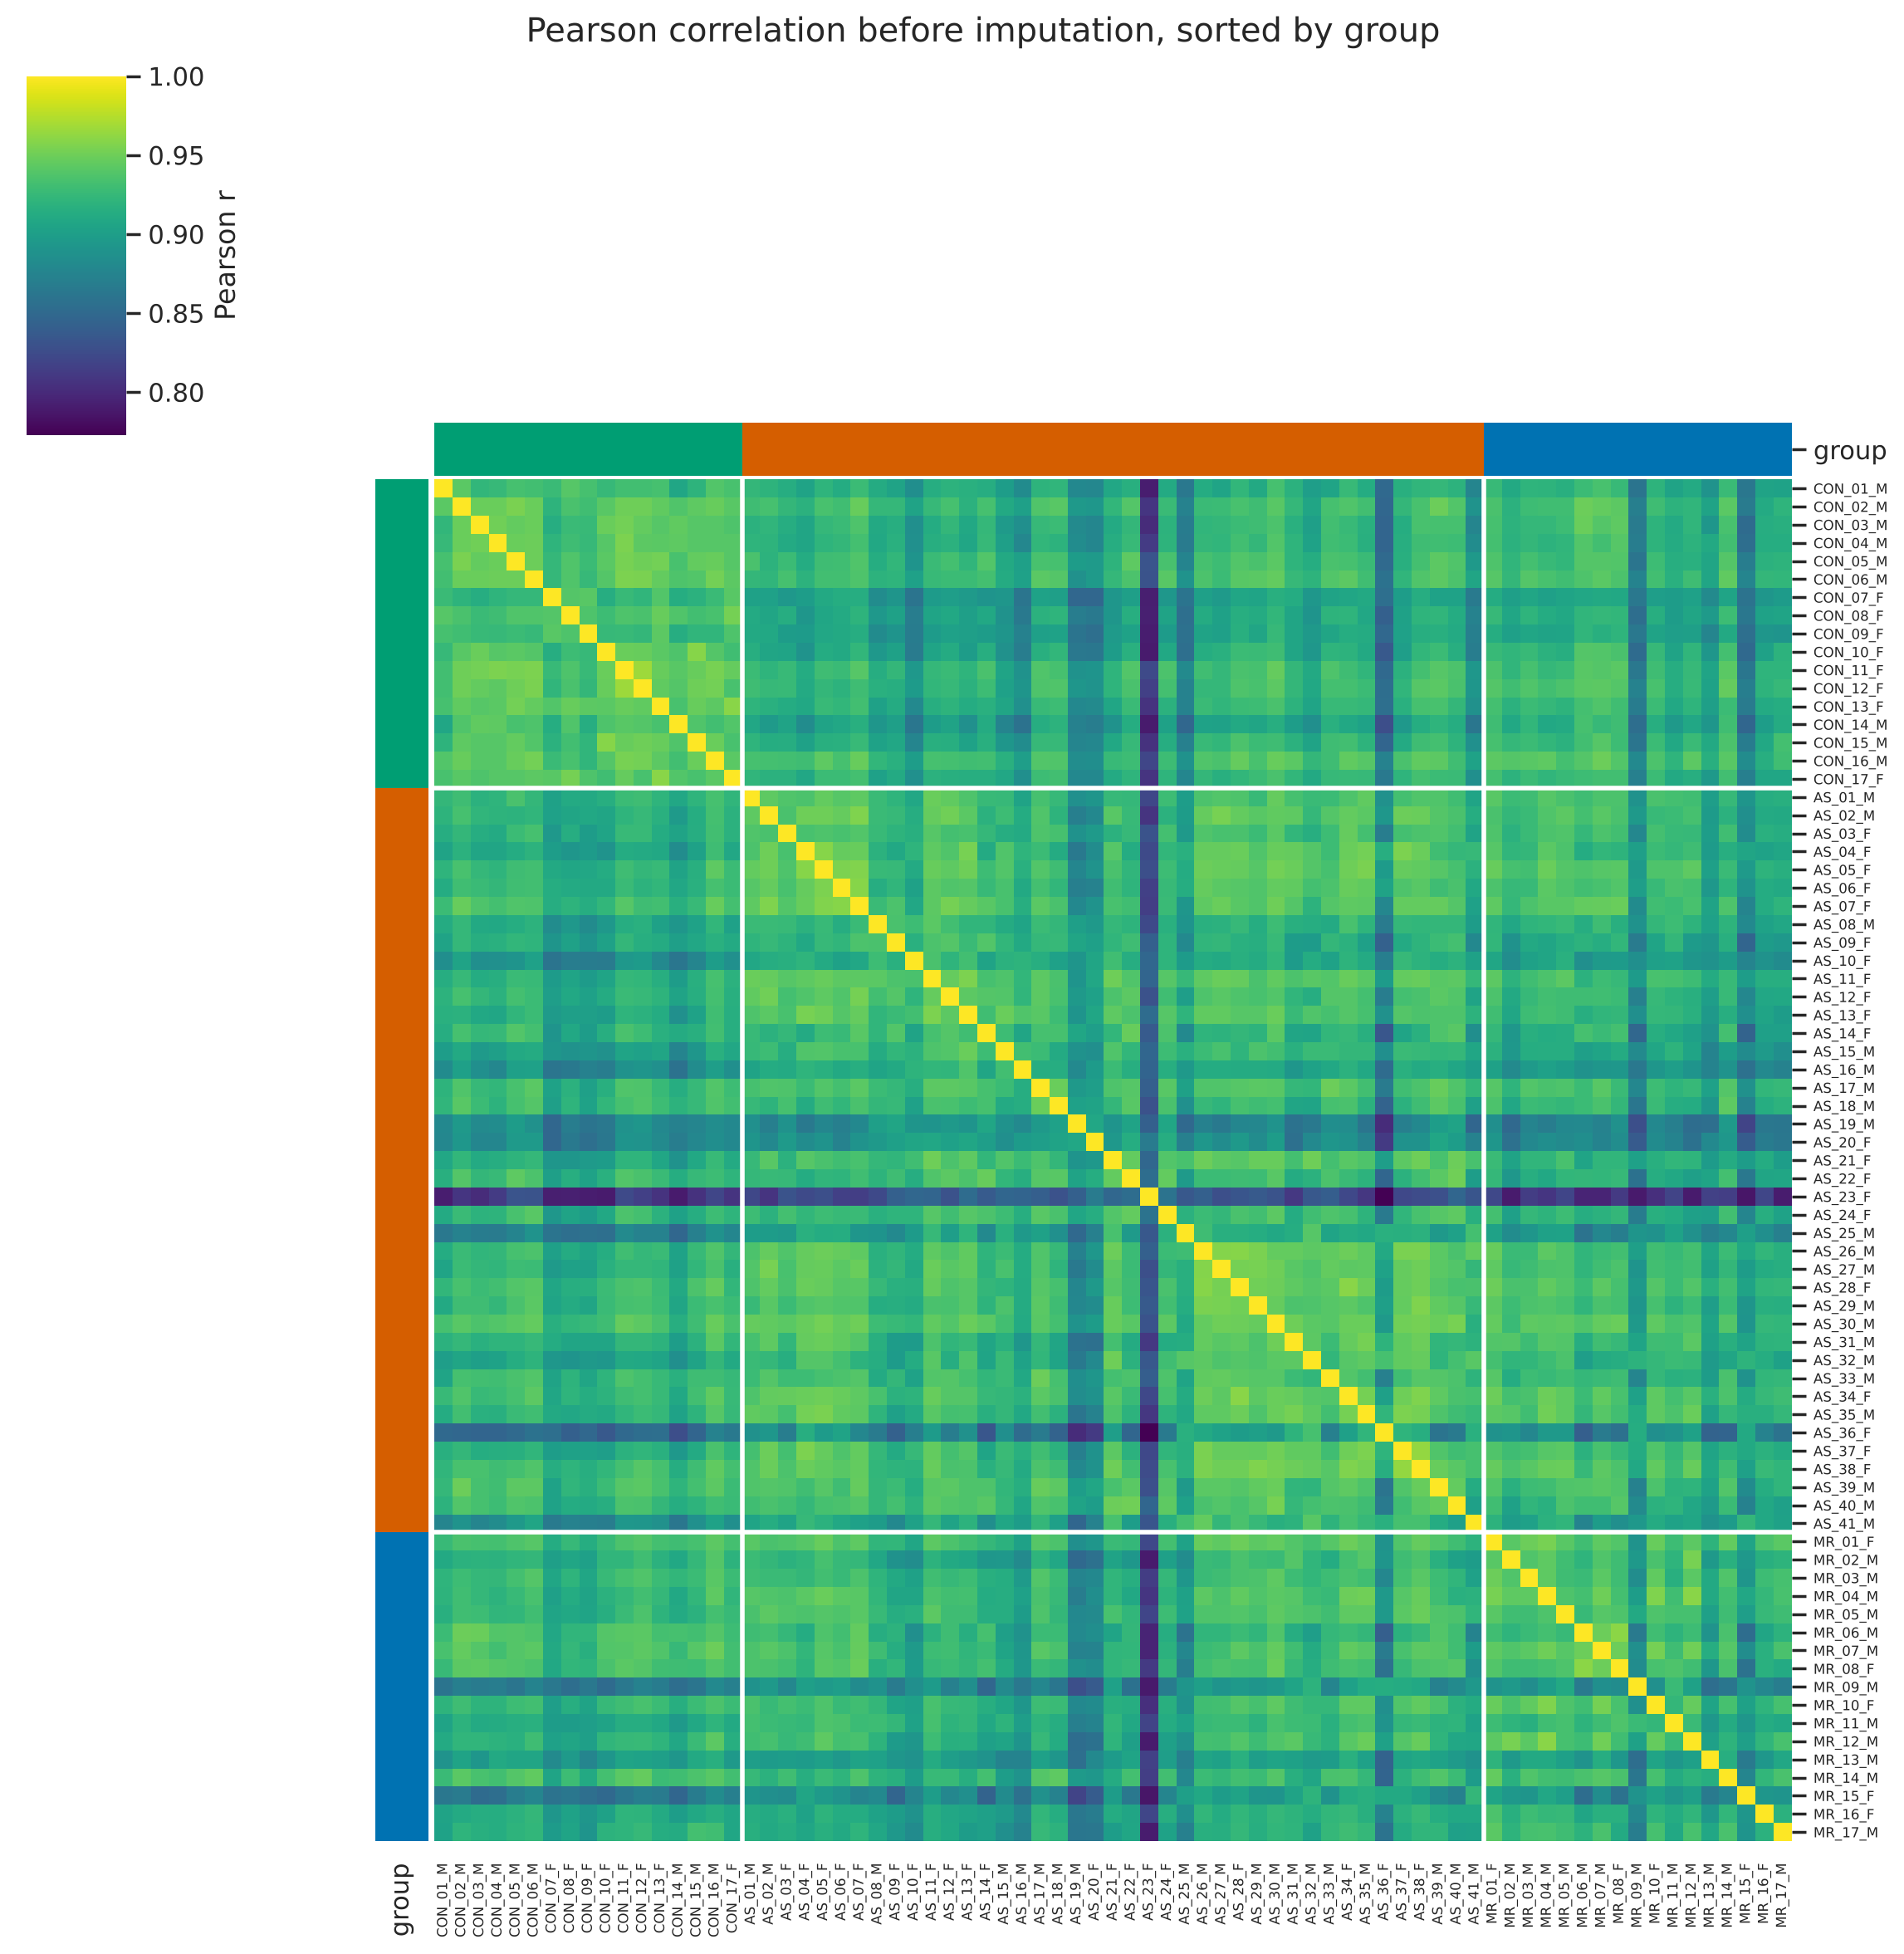

Lowest median correlation to other samples:
AS_23_F    0.822
AS_36_F    0.869
AS_19_M    0.879
MR_09_M    0.881
MR_15_F    0.883
dtype: float64


In [14]:
corr = log2[order].corr(method="pearson", min_periods=50)
g = sns.clustermap(corr, cmap="viridis", row_cluster=False, col_cluster=False,
                   col_colors=sample_colors[order], row_colors=sample_colors[order],
                   figsize=(12, 12), xticklabels=True, yticklabels=True,
                   cbar_kws={"label": "Pearson r"})
group_sizes = meta.loc[order, "group"].value_counts().reindex(GROUP_ORDER)
for edge in np.cumsum(group_sizes.values)[:-1]:
    g.ax_heatmap.axhline(edge, color="white", lw=2)
    g.ax_heatmap.axvline(edge, color="white", lw=2)
g.ax_heatmap.tick_params(labelsize=6)
g.figure.suptitle("Pearson correlation before imputation, sorted by group", y=1.01)
plt.show()

median_corr = corr.where(~np.eye(len(corr), dtype=bool)).median()
print("Lowest median correlation to other samples:")
print(median_corr.nsmallest(5).round(3))

## 14. Impute missing values (Perseus method)

Most statistics and PCA need a complete matrix. Section 5 showed that
missing values are mostly LOW-abundance proteins that fell below the
detection limit ("missing not at random"). So instead of filling them with
the mean (which would invent average-looking values), each missing value
is replaced by a random draw from a narrow normal distribution at the low
end of that sample's intensities, as Perseus does by default:
- `mean  = sample mean - 1.8 x sample SD    (shifted down by 1.8 SD)`
- `width = 0.3 x sample SD                  (0.3 times as wide)`

This is done per sample, on the median-normalized log2 values. A fixed
random seed makes the result the same every time you run the notebook.

Keep in mind: imputed values are guesses. They are fine for PCA and
clustering, but proteins with many imputed values should be interpreted
with care in differential testing.

Imputed 30702 values (10.4% of the matrix)


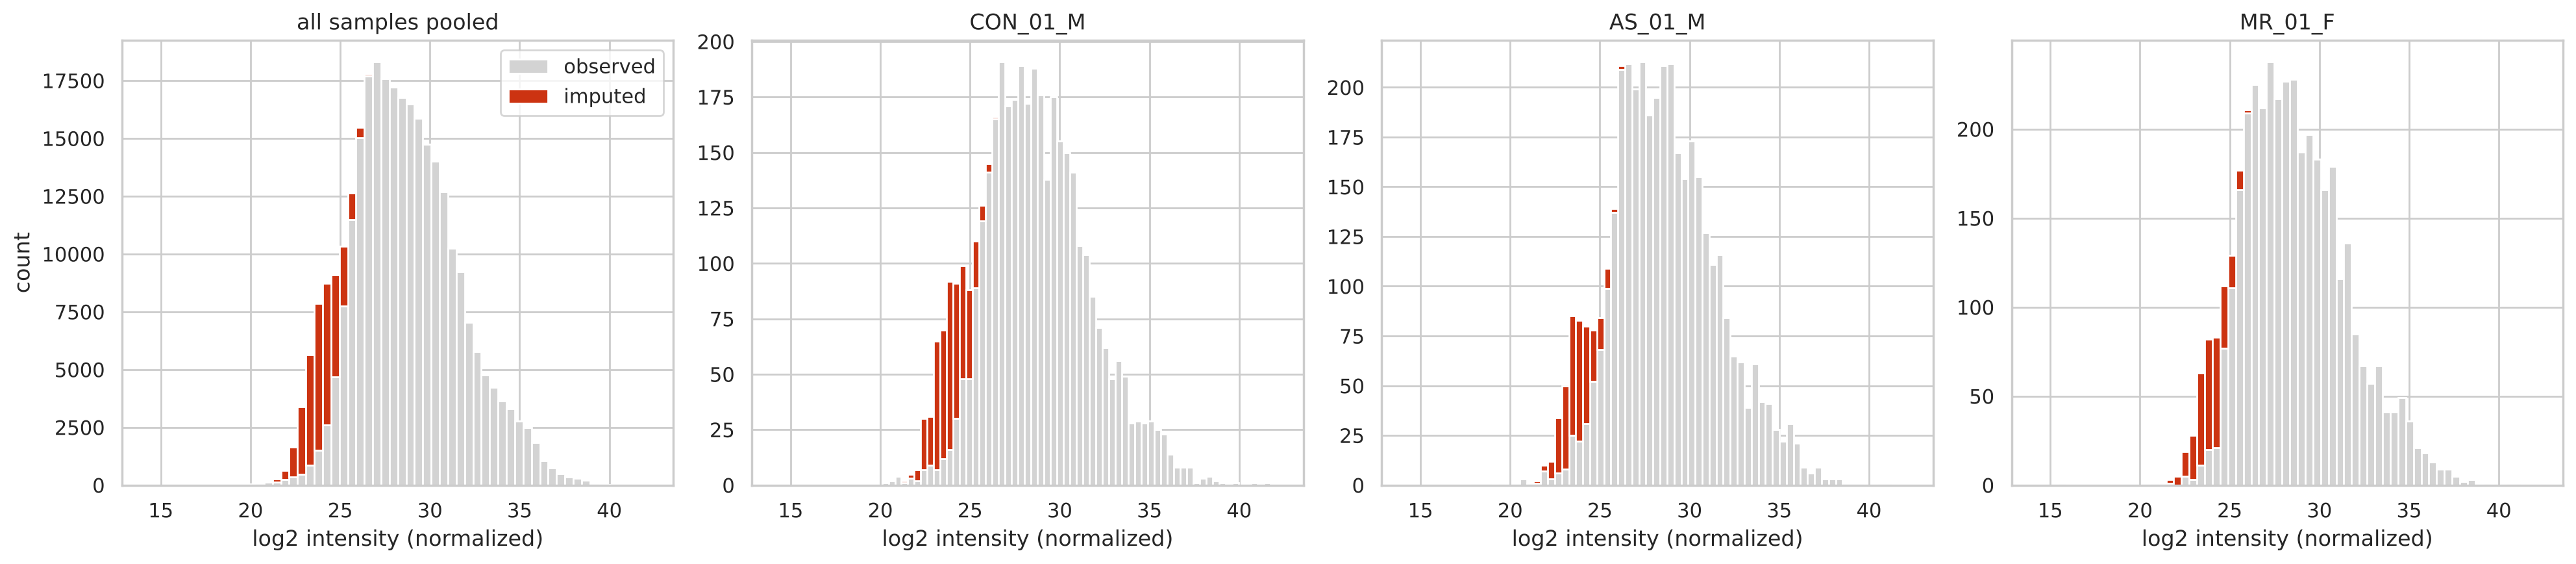

In [15]:
rng = np.random.default_rng(seed=42)
log2_imp = log2.copy()
is_imputed = log2.isna()
for s in log2.columns:
    obs = log2[s].dropna()
    n_miss = is_imputed[s].sum()
    log2_imp.loc[is_imputed[s].to_numpy(), s] = rng.normal(
        loc=obs.mean() - IMPUTE_DOWNSHIFT * obs.std(),
        scale=IMPUTE_WIDTH * obs.std(),
        size=n_miss)
print(f"Imputed {is_imputed.sum().sum()} values "
      f"({100 * is_imputed.mean().mean():.1f}% of the matrix)")

# Plot: observed (grey) vs imputed (red) values, pooled and for one sample
# per group. Imputed values should sit at the lower tail of the observed
# distribution, not in the middle and not far below it.
examples = [meta.index[meta["group"] == g][0] for g in GROUP_ORDER]
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5), sharex=True)
for ax, (title, sel) in zip(axes, [("all samples pooled", list(log2.columns))]
                            + [(s, [s]) for s in examples]):
    observed = log2_imp[sel].where(~is_imputed[sel]).stack()
    imputed = log2_imp[sel].where(is_imputed[sel]).stack()
    ax.hist([observed, imputed], bins=60, stacked=True,
            color=["lightgrey", "#CC3311"], label=["observed", "imputed"])
    ax.set_title(title)
    ax.set_xlabel("log2 intensity (normalized)")
axes[0].set_ylabel("count")
axes[0].legend()
show(fig)

## 15. Normality per protein within each group, split by sex

t-tests and ANOVA assume that, within each group, a protein's
values are roughly normally distributed. Here each protein is tested with
Shapiro-Wilk separately in the six subgroups (3 diagnoses x 2 sexes),
on the imputed data.

How to read it: if every protein were truly normal, about 5 % would get
p < 0.05 by chance and the p-value histogram would be flat (dashed line).
A peak near 0 means many proteins deviate from normality.

Caveats:
- Small subgroups (e.g. 5 female MR patients) have very little power, so
  "normal" there mostly means "too few patients to tell".
- Imputed values form a tight cluster at the low end, which can itself
  make a protein look non-normal. The titles therefore also show the
  rate for proteins with NO imputed values in that subgroup.

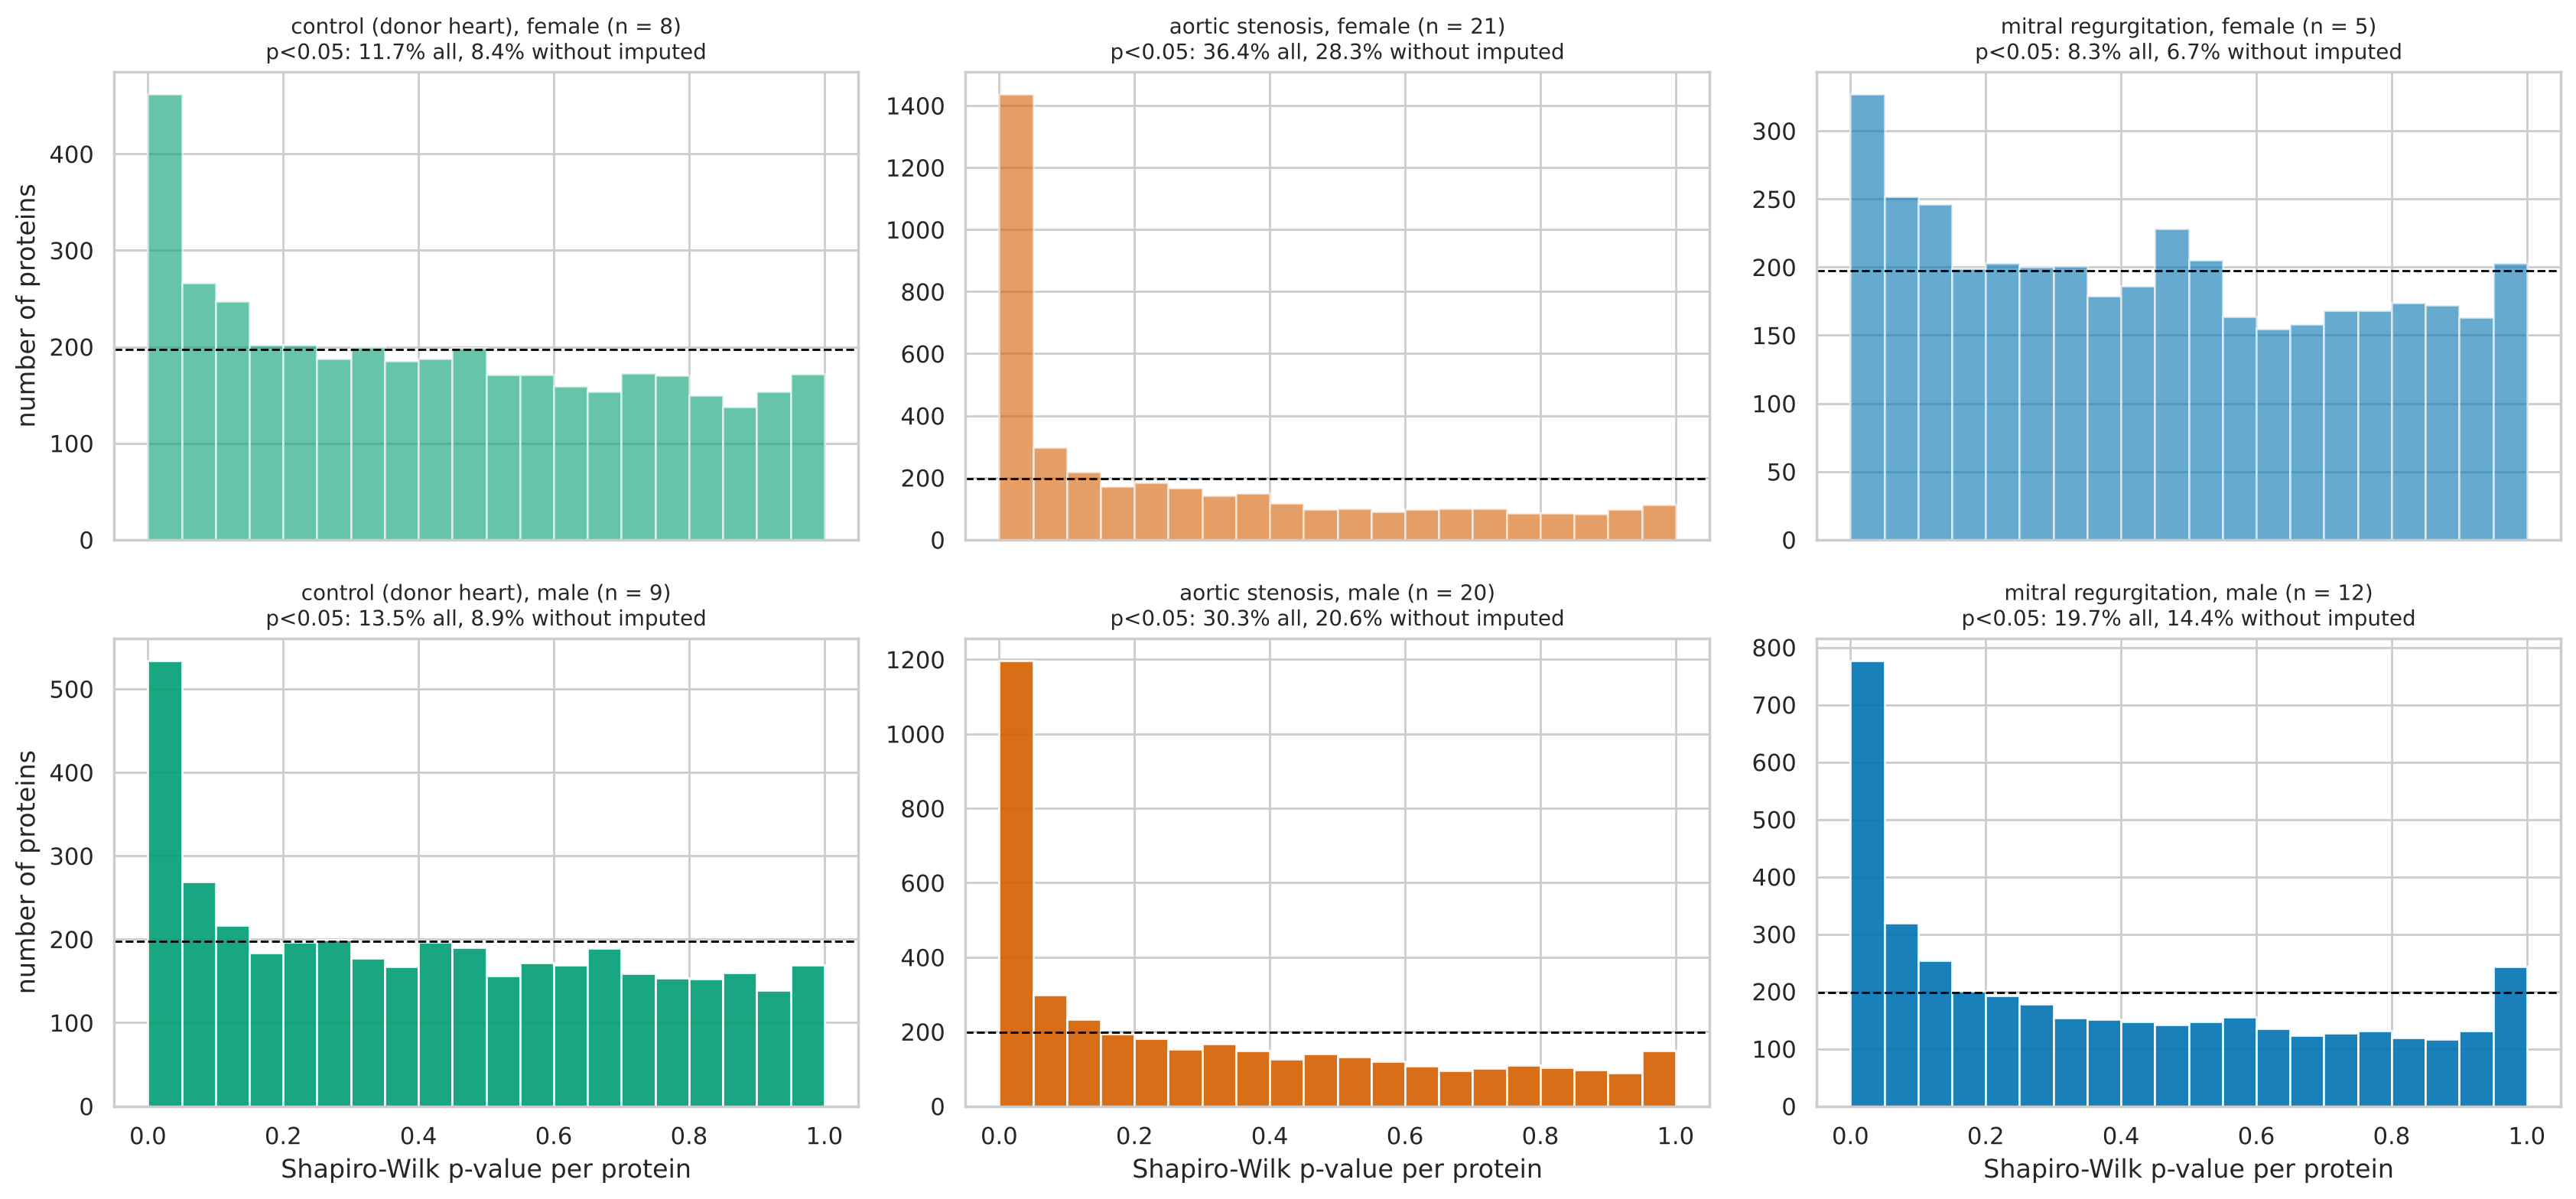

                              n_patients  % p<0.05 (all proteins)  % p<0.05 (no imputed values)
group                 sex                                                                      
aortic stenosis       female          21                     36.4                          28.3
                      male            20                     30.3                          20.6
control (donor heart) female           8                     11.7                           8.4
                      male             9                     13.5                           8.9
mitral regurgitation  female           5                      8.3                           6.7
                      male            12                     19.7                          14.4


In [16]:
from scipy import stats

subgroups = [(g, sx) for g in GROUP_ORDER for sx in ["female", "male"]]
norm_rows = []
for g, sx in subgroups:
    ids = meta.index[(meta["group"] == g) & (meta["sex"] == sx)]
    if len(ids) < 3:
        continue
    pvals = np.array([stats.shapiro(v).pvalue for v in log2_imp[ids].to_numpy()])
    no_imp = ~is_imputed[ids].any(axis=1).to_numpy()
    norm_rows.append(pd.DataFrame({"group": g, "sex": sx, "n": len(ids),
                                   "p": pvals, "no_imputed": no_imp}))
prot_norm = pd.concat(norm_rows, ignore_index=True)

fig, axes = plt.subplots(2, 3, figsize=(17, 8), sharex=True)
for (g, sx), sub in prot_norm.groupby(["group", "sex"]):
    ax = axes[["female", "male"].index(sx), GROUP_ORDER.index(g)]
    ax.hist(sub["p"], bins=20, range=(0, 1), color=GROUP_COLORS[g],
            alpha=0.9 if sx == "male" else 0.6)
    ax.axhline(len(sub) / 20, color="black", ls="--", lw=1)
    pct_all = 100 * (sub["p"] < 0.05).mean()
    pct_clean = 100 * (sub.loc[sub["no_imputed"], "p"] < 0.05).mean()
    ax.set_title(f"{g}, {sx} (n = {sub['n'].iloc[0]})\n"
                 f"p<0.05: {pct_all:.1f}% all, {pct_clean:.1f}% without imputed",
                 fontsize=10)
for ax in axes[1]:
    ax.set_xlabel("Shapiro-Wilk p-value per protein")
for ax in axes[:, 0]:
    ax.set_ylabel("number of proteins")
show(fig)

norm_summary = (prot_norm.groupby(["group", "sex"])
                .apply(lambda d: pd.Series({
                    "n_patients": d["n"].iloc[0],
                    "% p<0.05 (all proteins)": 100 * (d["p"] < 0.05).mean(),
                    "% p<0.05 (no imputed values)":
                        100 * (d.loc[d["no_imputed"], "p"] < 0.05).mean()}),
                       include_groups=False)
                .round(1))
print(norm_summary.astype({"n_patients": int}).to_string())

### What this means for the statistics

If all proteins were normally distributed, only about 5 % would reach p < 0.05 here by chance. The observed rates are clearly higher:

| | female | male |
|---|---|---|
| Control | 12 % (n = 8) | 14 % (n = 9) |
| Aortic stenosis | 36 % (n = 21) | 30 % (n = 20) |
| Mitral regurgitation | 8 % (n = 5) | 20 % (n = 12) |

So not every protein is affected, but a substantial share is: in aortic stenosis about a third of proteins deviate, and still 21–28 % when proteins with imputed values are left out. In the small subgroups (e.g. 5 female MR patients) normality cannot really be checked at all, because the test has almost no power. Since we cannot rely on normality for every protein, we use **non-parametric tests**, which compare ranks instead of the values themselves and make no assumption about the shape of the distribution:

- **Mann–Whitney U test** (Wilcoxon rank-sum) for two-group comparisons (AS vs control, AS vs MR, MR vs control)
- **Kruskal–Wallis test** to compare all three groups at once
- **Benjamini–Hochberg correction** of the p-values, because thousands of proteins are tested at once (otherwise ~5 % false positives)

Rank-based tests are also less affected by outlier samples such as AS_23_F. The trade-off: with small groups they have somewhat less power than a t-test, and imputed values all sit at the low end, so proteins with many imputed values should be interpreted with care.

## 16. PCA: all samples

PCA summarizes thousands of proteins into a few axes (principal components) that capture the largest differences between samples. Samples that lie close together have similar proteomes. If disease changes the proteome, the groups should separate along PC1 or PC2. This first PCA includes all 75 samples to give an overview: does disease or sex drive the main differences, and are there outliers far from everyone else?

Input: filtered, log2, median-normalized, imputed data. Each protein is centred (mean subtracted) before PCA. Colour = group, shape = sex (circle = male, triangle = female).

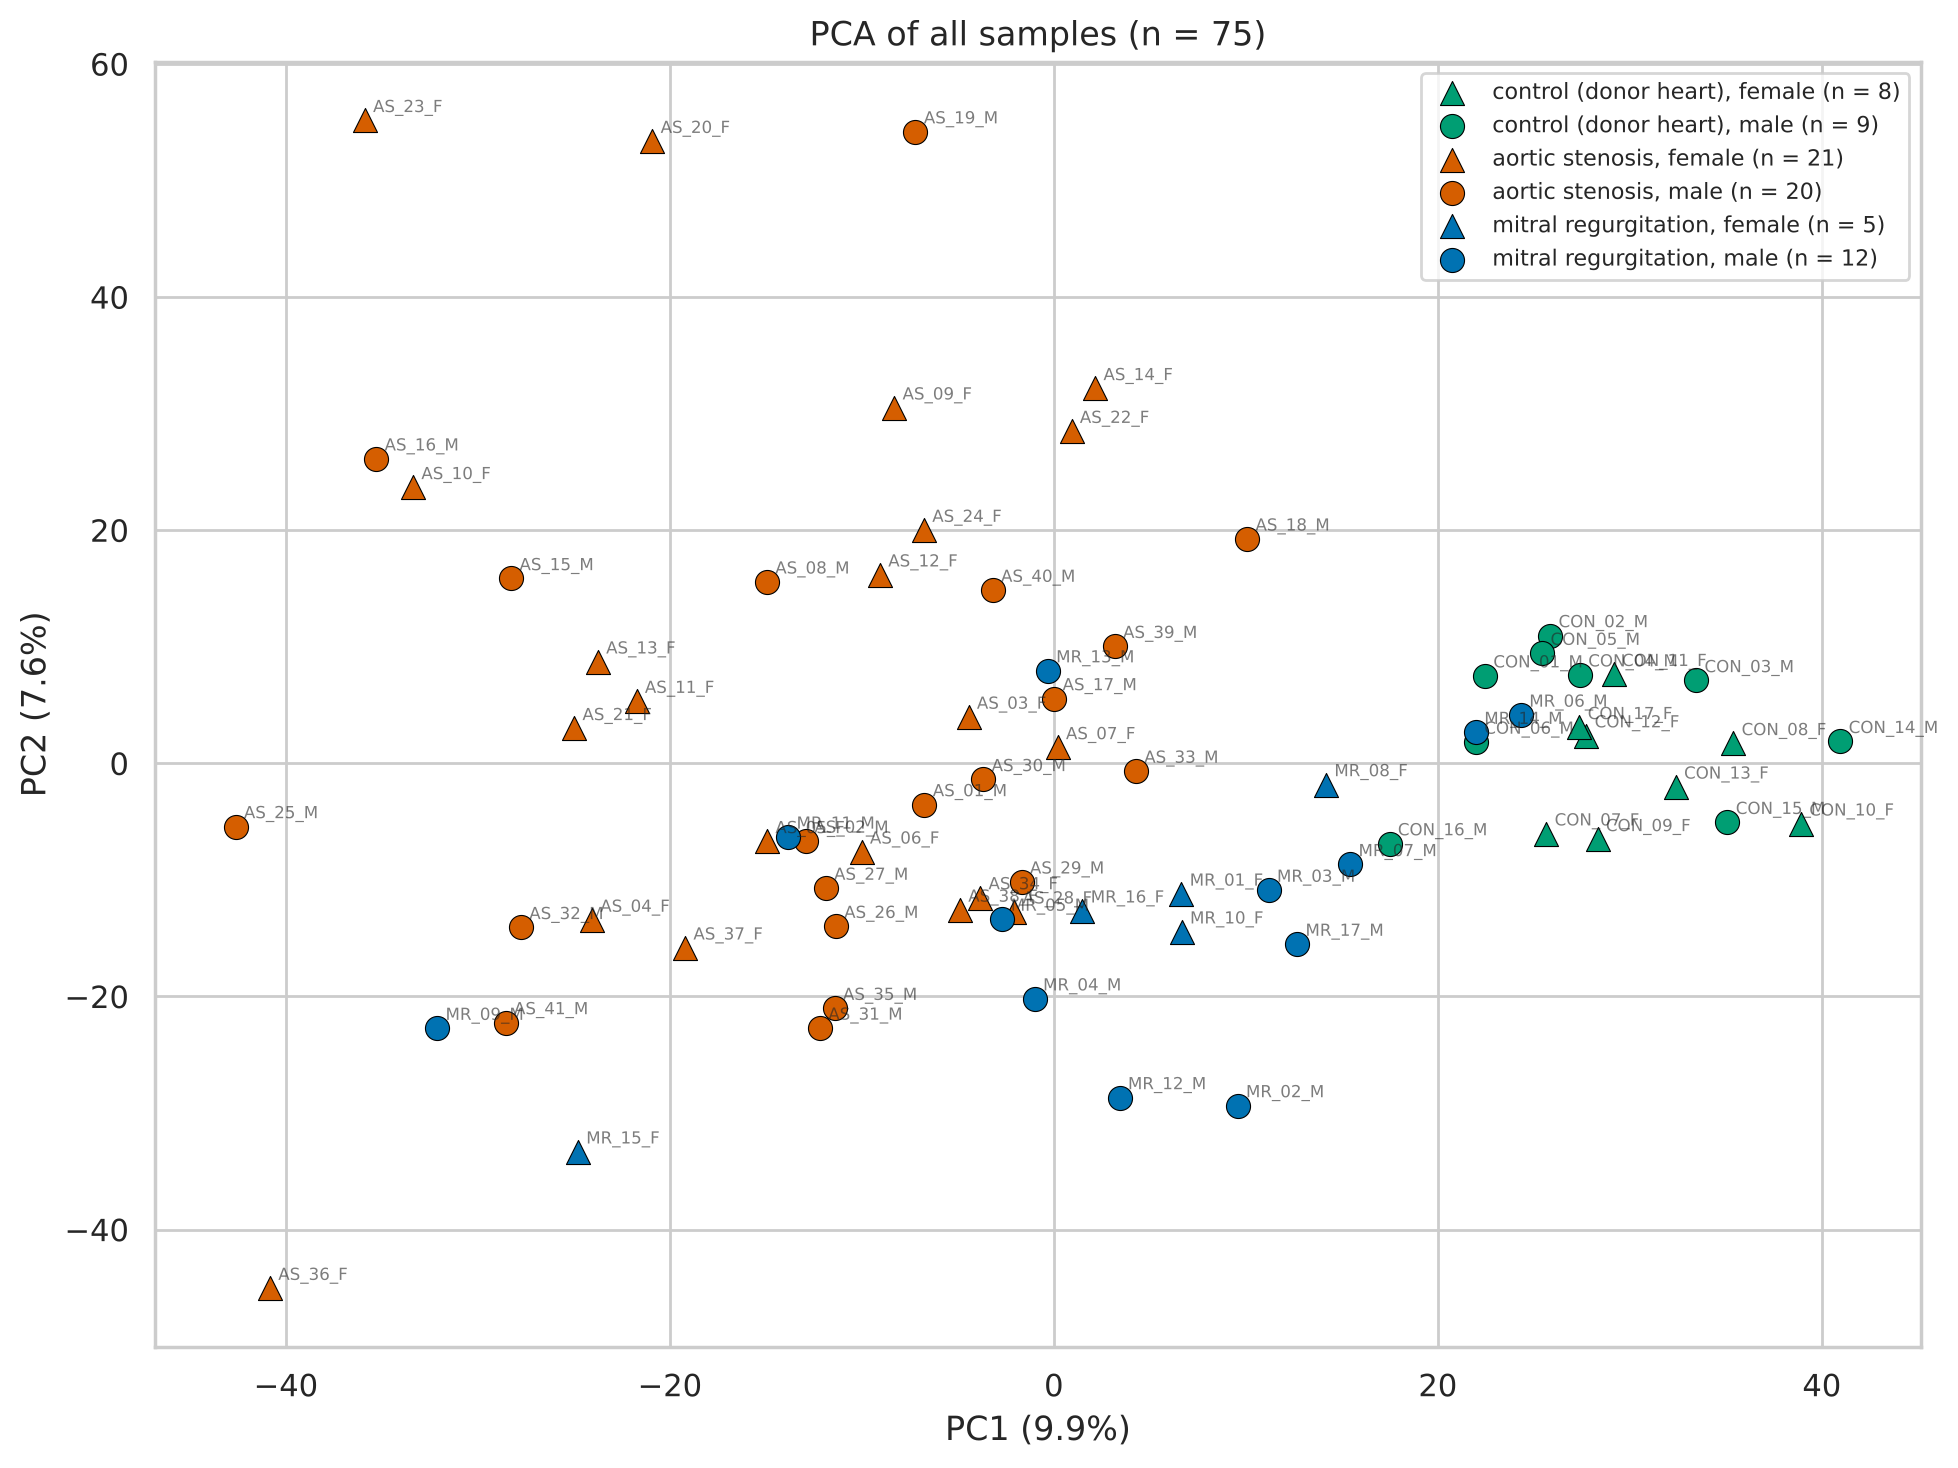

In [17]:
def run_pca(data, n=2):
    """PCA via SVD. data: proteins x samples. Returns scores and % variance."""
    X = data.T.to_numpy()
    X = X - X.mean(axis=0)
    U, S, _ = np.linalg.svd(X, full_matrices=False)
    scores = pd.DataFrame(U[:, :n] * S[:n], index=data.columns,
                          columns=[f"PC{k + 1}" for k in range(n)])
    return scores, 100 * S[:n] ** 2 / (S ** 2).sum()


scores_all, var_all = run_pca(log2_imp)
scores_all = scores_all.join(meta[["group", "sex"]])

fig, ax = plt.subplots(figsize=(10, 7.5))
for g_ in GROUP_ORDER:
    for sx in ["female", "male"]:
        sub = scores_all[(scores_all["group"] == g_) & (scores_all["sex"] == sx)]
        ax.scatter(sub["PC1"], sub["PC2"], c=GROUP_COLORS[g_],
                   marker=SEX_MARKERS[sx], s=75, edgecolor="black",
                   linewidth=0.4, label=f"{g_}, {sx} (n = {len(sub)})")
for s, row in scores_all.iterrows():
    ax.annotate(s, (row.PC1, row.PC2), fontsize=6, alpha=0.6,
                xytext=(3, 3), textcoords="offset points")
ax.set_xlabel(f"PC1 ({var_all[0]:.1f}%)")
ax.set_ylabel(f"PC2 ({var_all[1]:.1f}%)")
ax.set_title(f"PCA of all samples (n = {len(scores_all)})")
ax.legend(fontsize=8)
show(fig)

## 17. PCA: pairwise comparisons on the processed data

Each comparison gets its own PCA, computed only on the samples of those two
groups, so the axes describe what differs between exactly these groups.

Input: filtered, log2, median-normalized, imputed data. Each protein is
centred (mean subtracted) before PCA. Colour = group, shape = sex
(circle = male, triangle = female).

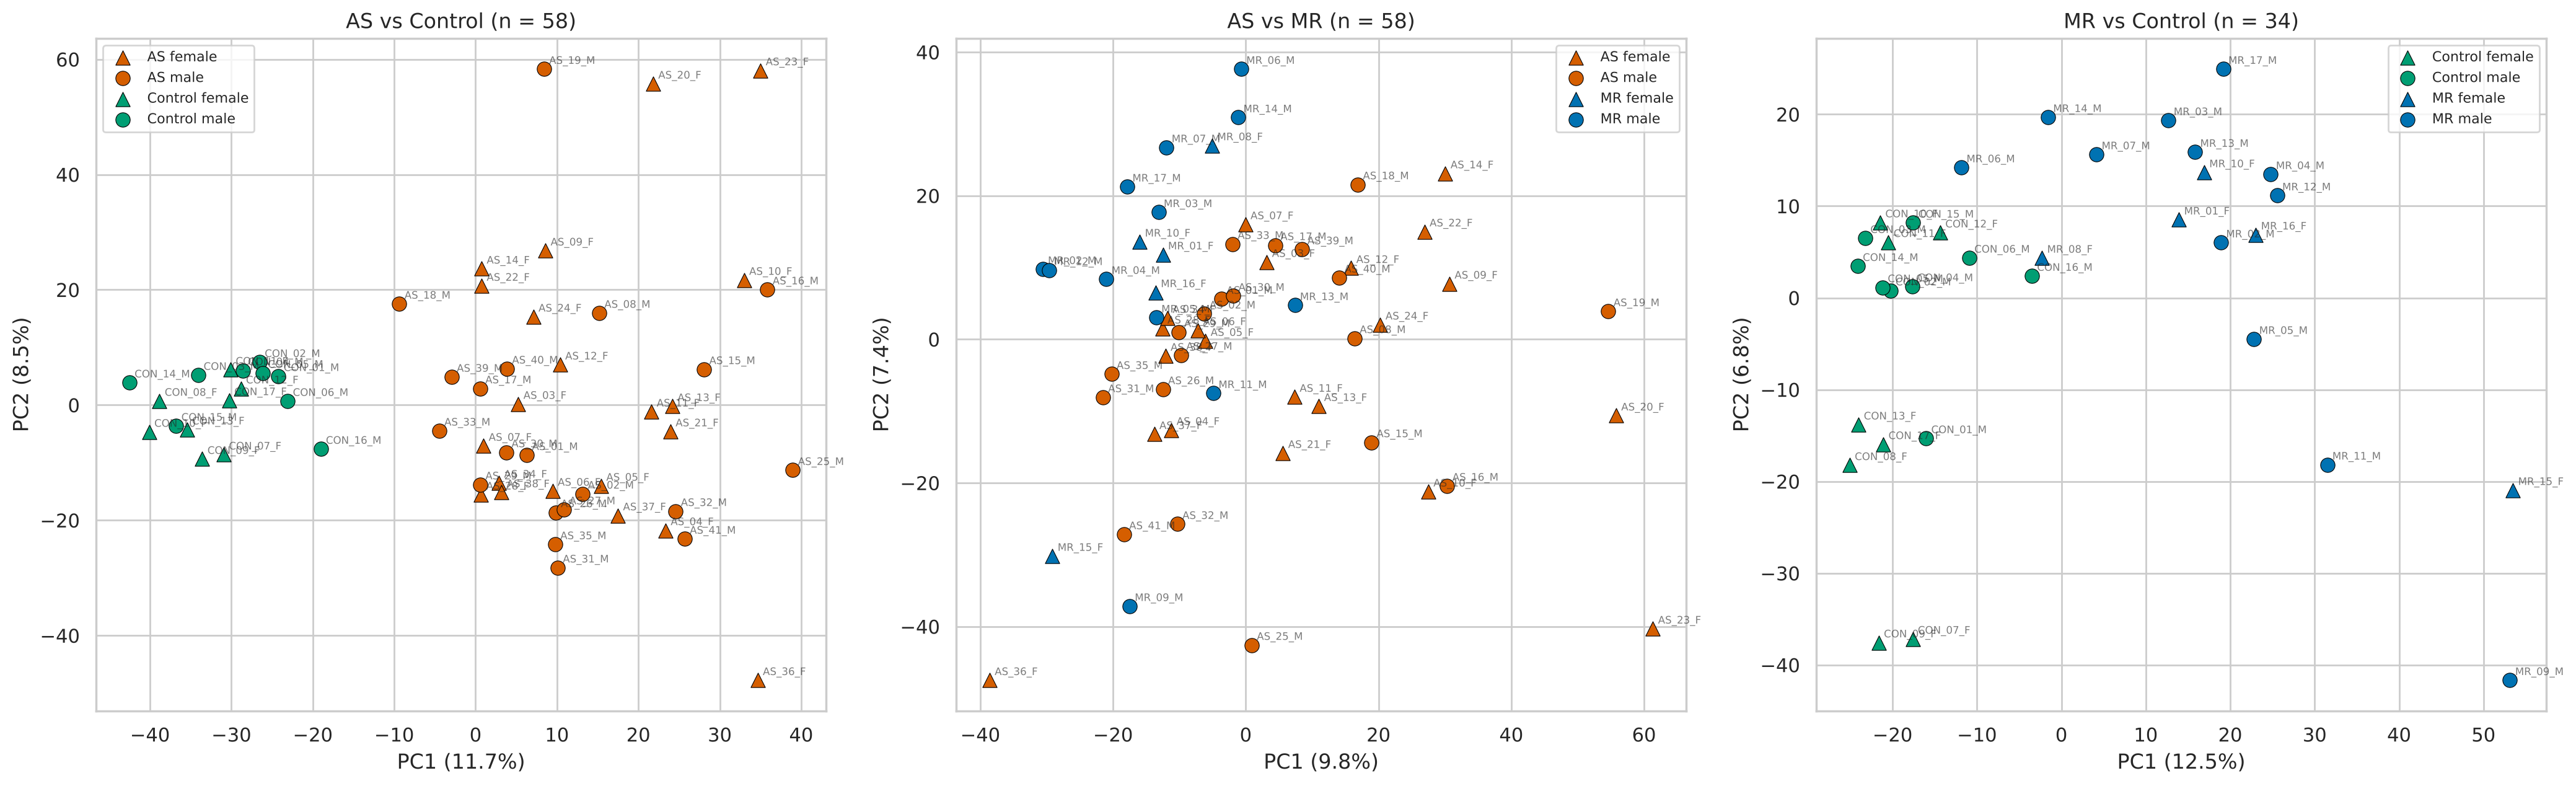

In [18]:
comparisons = [("aortic stenosis", "control (donor heart)"),
               ("aortic stenosis", "mitral regurgitation"),
               ("mitral regurgitation", "control (donor heart)")]
short = {"aortic stenosis": "AS", "mitral regurgitation": "MR",
         "control (donor heart)": "Control"}

fig, axes = plt.subplots(1, 3, figsize=(21, 6.5))
for ax, (g1, g2) in zip(axes, comparisons):
    ids = meta.index[meta["group"].isin([g1, g2])]
    scores, var = run_pca(log2_imp[ids])
    scores = scores.join(meta[["group", "sex"]])
    for (g, sx), sub in scores.groupby(["group", "sex"]):
        ax.scatter(sub["PC1"], sub["PC2"], c=GROUP_COLORS[g],
                   marker=SEX_MARKERS[sx], s=70, edgecolor="black",
                   linewidth=0.4, label=f"{short[g]} {sx}")
    for s, row in scores.iterrows():
        ax.annotate(s, (row.PC1, row.PC2), fontsize=6, alpha=0.6,
                    xytext=(3, 3), textcoords="offset points")
    ax.set_xlabel(f"PC1 ({var[0]:.1f}%)")
    ax.set_ylabel(f"PC2 ({var[1]:.1f}%)")
    ax.set_title(f"{short[g1]} vs {short[g2]} (n = {len(ids)})")
    ax.legend(fontsize=8)
show(fig)

## 18. Sample-sample correlation after processing, sorted by group and sex

Same idea as the correlation heatmap before imputation, but on the final processed data (normalized and
imputed) and with samples sorted by group, then by sex within each group.
The two colour bars show group (top) and sex (bottom: dark = male,
light = female). This shows whether patients of the same group, and of
the same sex within a group, are more similar to each other than to the
rest, and whether outliers from before imputation are still outliers.

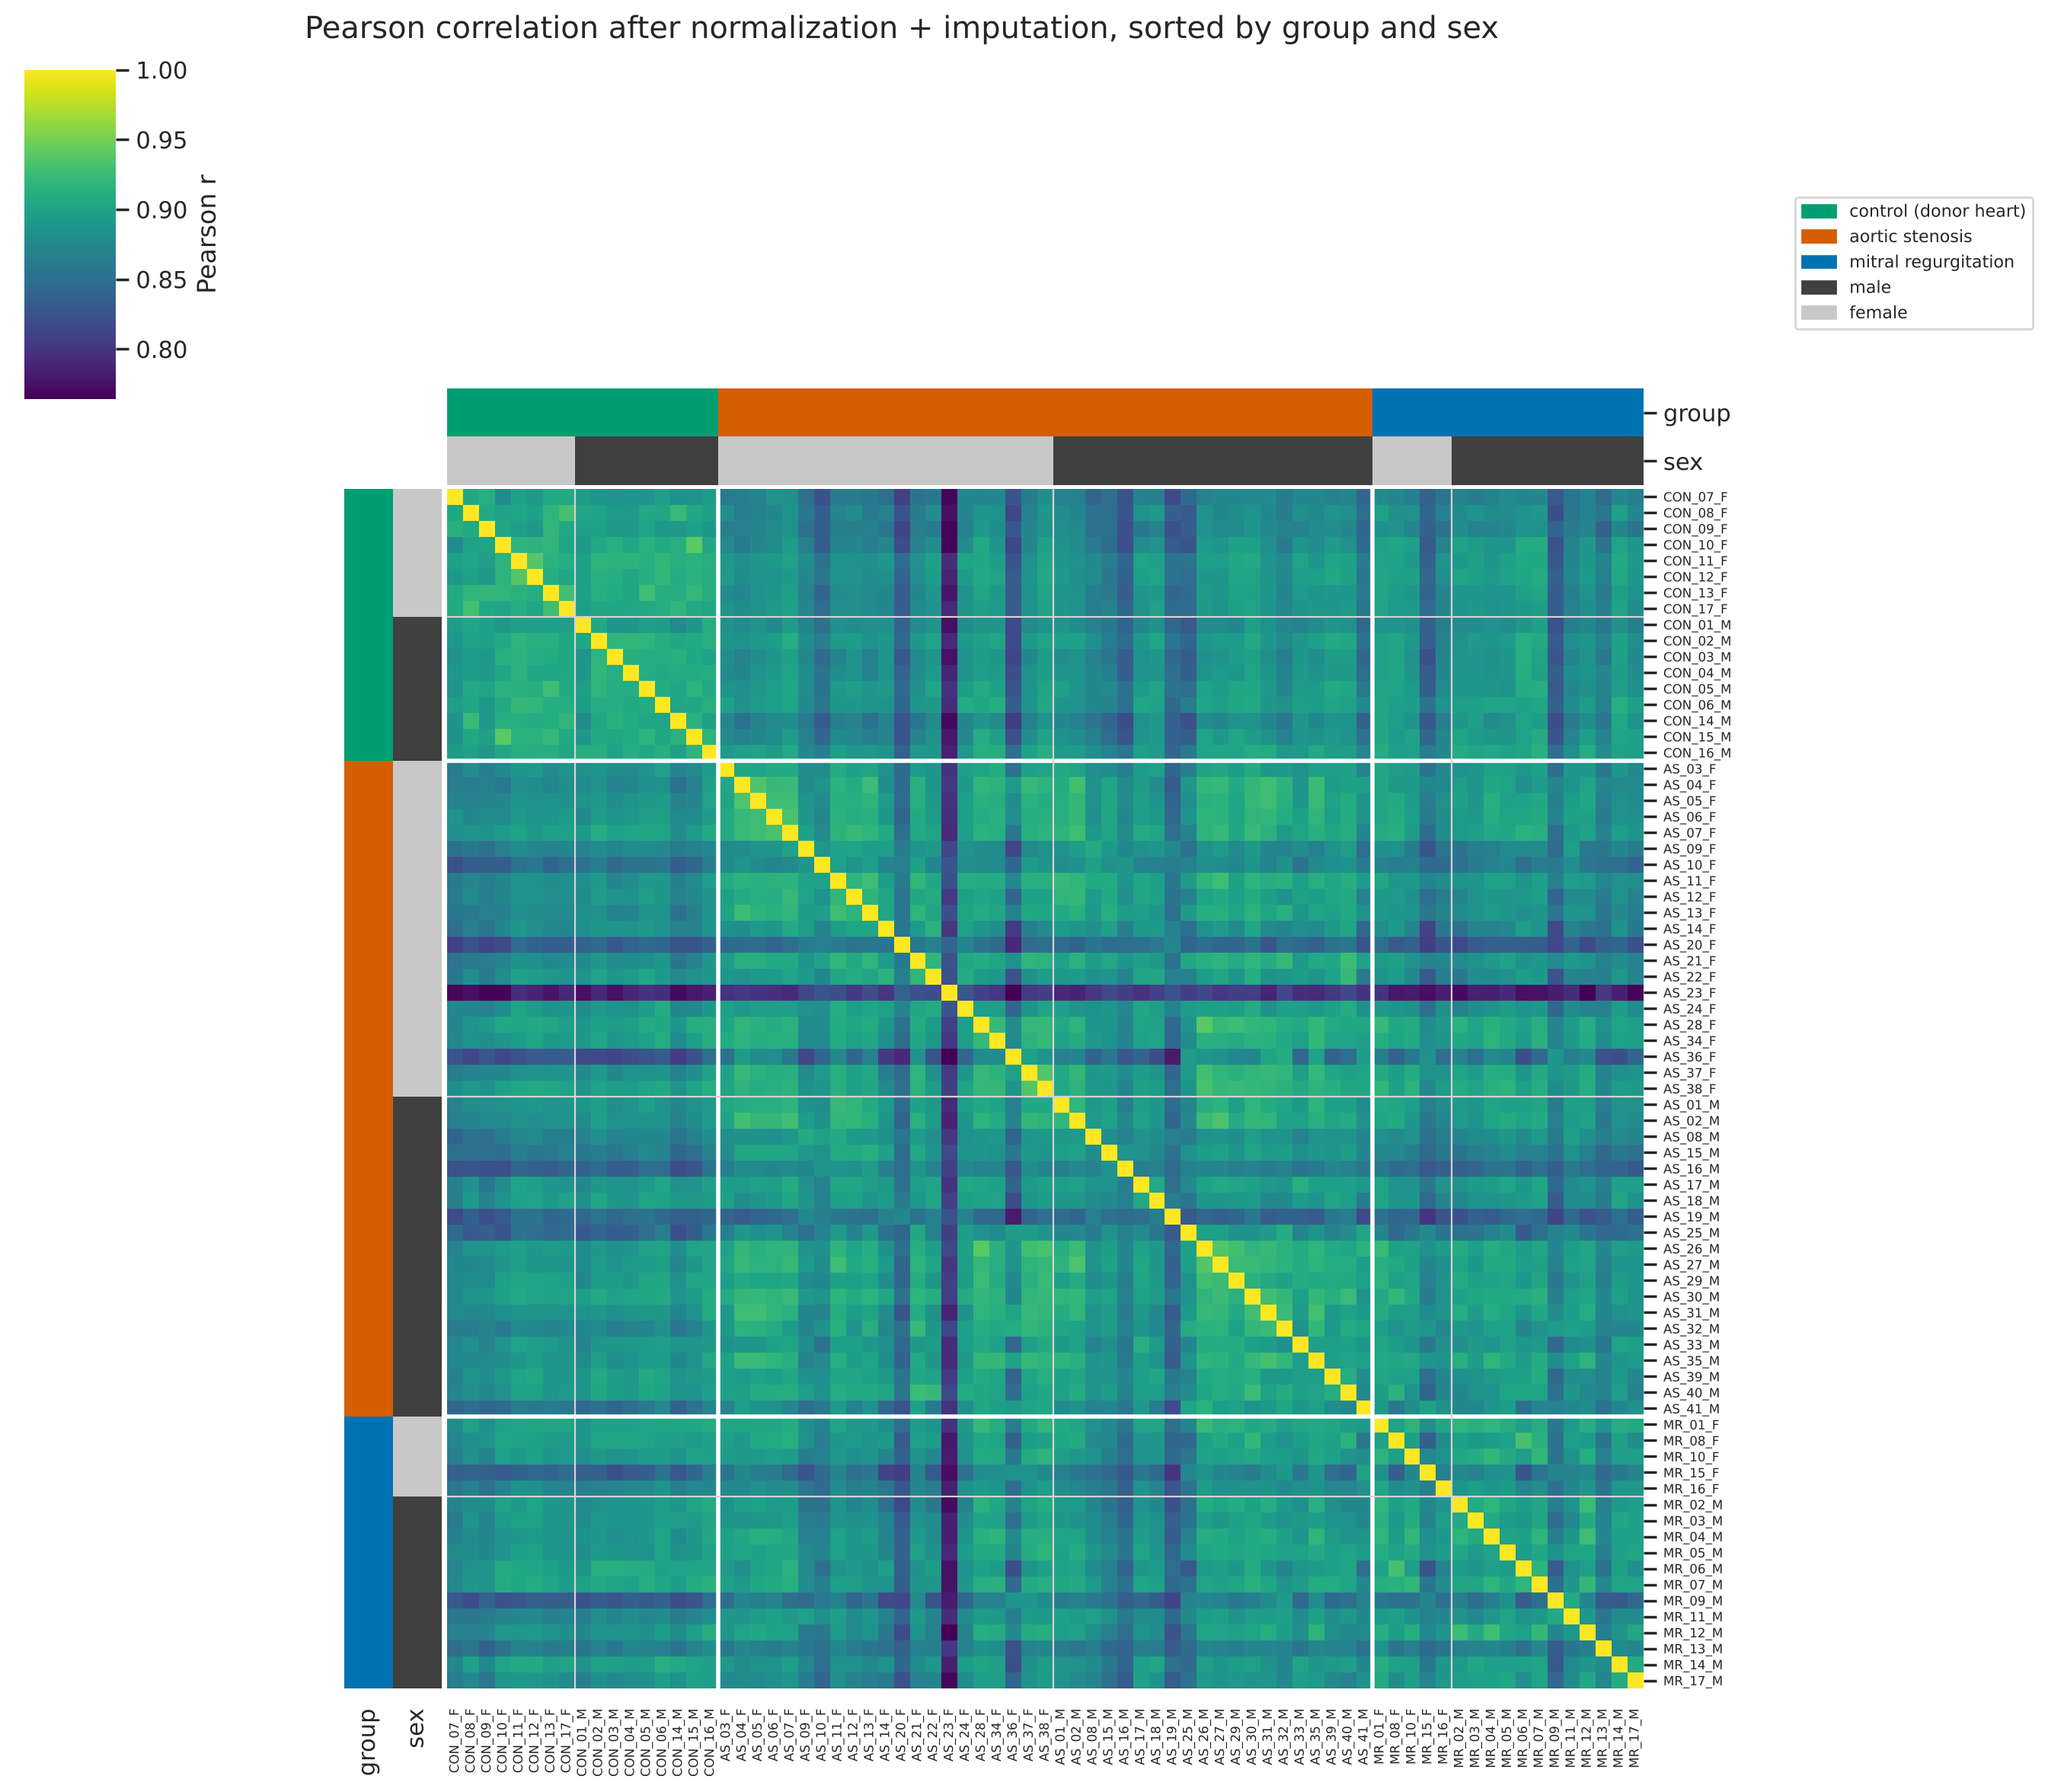

In [19]:
order_sex = (meta.assign(g=pd.Categorical(meta["group"], GROUP_ORDER),
                         name=meta.index)
             .sort_values(["g", "sex", "name"]).index)
annot_colors = pd.DataFrame({
    "group": meta.loc[order_sex, "group"].map(GROUP_COLORS),
    "sex": meta.loc[order_sex, "sex"].map(SEX_COLORS),
})
corr_imp = log2_imp[order_sex].corr(method="pearson")
g = sns.clustermap(corr_imp, cmap="viridis", row_cluster=False,
                   col_cluster=False, col_colors=annot_colors,
                   row_colors=annot_colors, figsize=(12, 12),
                   xticklabels=True, yticklabels=True,
                   cbar_kws={"label": "Pearson r"})
grp_sizes = meta.loc[order_sex, "group"].value_counts().reindex(GROUP_ORDER)
grp_edges = np.cumsum(grp_sizes.values)
sex_edges = np.cumsum(meta.loc[order_sex].groupby(
    [pd.Categorical(meta.loc[order_sex, "group"], GROUP_ORDER), "sex"],
    observed=True).size().values)
for e in sex_edges[:-1]:
    lw, col = (2, "white") if e in grp_edges else (0.8, "lightgrey")
    g.ax_heatmap.axhline(e, color=col, lw=lw)
    g.ax_heatmap.axvline(e, color=col, lw=lw)
g.ax_heatmap.tick_params(labelsize=6)
legend_items = ([plt.Rectangle((0, 0), 1, 1, color=GROUP_COLORS[x]) for x in GROUP_ORDER]
                + [plt.Rectangle((0, 0), 1, 1, color=SEX_COLORS[x]) for x in SEX_COLORS])
g.ax_heatmap.legend(legend_items, GROUP_ORDER + list(SEX_COLORS),
                    loc="upper left", bbox_to_anchor=(1.12, 1.25), fontsize=8)
g.figure.suptitle("Pearson correlation after normalization + imputation, "
                  "sorted by group and sex", y=1.01)
plt.show()

### Why the samples look less similar after processing, and why that is not a problem

The correlations here are lower than in the heatmap before imputation (median r ≈ 0.89 instead of ≈ 0.93), so the matrix looks darker. This is not because the data got worse:

- **Median normalization does not change Pearson correlation at all**, because shifting a whole sample up or down does not change how its proteins line up with another sample.
- **Before imputation**, each pair of samples was compared only on proteins measured in both. These are mostly abundant, well-measured proteins that agree closely.
- **After imputation**, all proteins are included, and about 10 % of the values are random draws from the low-intensity range, made independently for each sample. Random values do not correlate with anything, so they pull every correlation down a little.

What matters is the *pattern*, and that is unchanged: samples correlate slightly better within their own group than between groups both before and after imputation (the gap stays about the same), and the same samples (AS_23_F, AS_36_F, AS_19_M, MR_09_M) stand out as outliers. To judge sample quality, the heatmap before imputation is the fairer view because it uses only real measurements. Imputation is there to give PCA and the statistical tests a complete matrix, not to make samples look alike.

## 19. Flag unusual samples

Several samples stood out repeatedly in the plots above. Here this is made objective: four QC measures are computed for every sample, and a sample gets a flag for each measure where it is an outlier by **Tukey's rule** (more than 1.5 × the interquartile range below the 25th or above the 75th percentile of all samples, the same rule a boxplot uses for its outlier dots):

| measure | flagged if | what it suggests |
|---|---|---|
| median correlation to other samples (before imputation) | too low | proteome differs from everyone else: tissue, sampling or measurement problem |
| proteins quantified | too low | little material or a poor LC-MS run |
| median-normalization correction (absolute) | too large | loading or measurement offset |
| distance to own group centre in the PCA (PC1–PC5) | too large | atypical for its group |

Samples are **flagged, not removed**. A sample with several flags is a strong candidate for exclusion, but the decision should be made deliberately, e.g. by running the statistics with and without the flagged samples and checking whether the conclusions change. To exclude samples later, filter them out right after loading the data.

In [20]:
def tukey_flag(values, side):
    """True where a value lies outside 1.5 x IQR on the given side."""
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    return values < q1 - 1.5 * iqr if side == "low" else values > q3 + 1.5 * iqr


# Distance of each sample to the median of its own group in PC1-PC5
scores5, _ = run_pca(log2_imp, n=5)
centres = scores5.groupby(meta["group"]).transform("median")
pca_distance = np.sqrt(((scores5 - centres) ** 2).sum(axis=1))

sample_flags = pd.DataFrame({
    "group": meta.loc[order, "group"],
    "sex": meta.loc[order, "sex"],
    "median_corr": median_corr[order].round(3),
    "proteins_quantified": n_ident[order],
    "abs_norm_correction": correction[order].abs().round(2),
    "pca_distance": pca_distance[order].round(1),
})
sample_flags["flag_low_corr"] = tukey_flag(sample_flags["median_corr"], "low")
sample_flags["flag_few_proteins"] = tukey_flag(sample_flags["proteins_quantified"], "low")
sample_flags["flag_norm_shift"] = tukey_flag(sample_flags["abs_norm_correction"], "high")
sample_flags["flag_pca_distance"] = tukey_flag(sample_flags["pca_distance"], "high")
flag_cols = [c for c in sample_flags.columns if c.startswith("flag_")]
sample_flags["n_flags"] = sample_flags[flag_cols].sum(axis=1)

flagged = sample_flags[sample_flags["n_flags"] > 0].sort_values("n_flags", ascending=False)
print(f"{len(flagged)} of {len(sample_flags)} samples flagged on at least one measure")
flagged

12 of 75 samples flagged on at least one measure


,group,sex,median_corr,proteins_quantified,abs_norm_correction,pca_distance,flag_low_corr,flag_few_proteins,flag_norm_shift,flag_pca_distance,n_flags
AS_23_F,aortic stenosis,female,0.822,2717,0.63,87.0,True,True,True,True,4
AS_19_M,aortic stenosis,male,0.879,3157,0.15,66.3,True,True,False,True,3
AS_20_F,aortic stenosis,female,0.884,2946,0.18,64.1,True,True,False,True,3
MR_09_M,mitral regurgitation,male,0.881,3537,0.26,58.2,True,False,False,True,2
AS_36_F,aortic stenosis,female,0.869,3635,0.08,61.6,True,False,False,True,2
AS_16_M,aortic stenosis,male,0.901,3129,0.24,34.6,False,True,False,False,1
AS_10_F,aortic stenosis,female,0.904,3256,0.08,41.4,False,True,False,False,1
AS_14_F,aortic stenosis,female,0.920,3387,0.28,38.6,False,False,True,False,1
AS_25_M,aortic stenosis,male,0.894,3466,0.16,45.1,True,False,False,False,1
AS_22_F,aortic stenosis,female,0.923,3432,0.30,33.5,False,False,True,False,1


## 20. Save the processed data to Excel

Writes one Excel file, `PR1_processed_data.xlsx`, next to this notebook. All filtering steps above are applied (contaminants, reverse hits, only-by-site and fragments removed; proteins with < 60 % values in every group removed). Sheets:
- **imputed**: log2, median-normalized and imputed values (the input for statistics)
- **not_imputed**: the same before imputation, with missing values left empty
- **imputed_mask**: TRUE where a value was imputed
- **sample_qc**: QC measures and outlier flags for every sample

The protein sheets start with the protein annotation and two flags: `single_peptide` (only one razor + unique peptide) and `n_imputed_values`. The sample columns of the protein sheets are sorted in the same order as the plots.

In [ ]:
OUT_FILE = "PR1_processed_data.xlsx"

annotation = df_kept.iloc[:, :FIRST_INTENSITY_COL].drop(columns=FILTER_COLS)
annotation["single_peptide"] = np.asarray(single_peptide)
annotation["n_imputed_values"] = is_imputed.sum(axis=1).to_numpy()

sample_qc = sample_flags.copy()
sample_qc["n_imputed"] = is_imputed[order].sum()

with pd.ExcelWriter(OUT_FILE) as writer:
    for data, sheet in [(log2_imp, "imputed"),
                        (log2, "not_imputed"),
                        (is_imputed, "imputed_mask")]:
        out = pd.concat([annotation, data[order].reset_index(drop=True)], axis=1)
        out.to_excel(writer, sheet_name=sheet, index=False)
    sample_qc.to_excel(writer, sheet_name="sample_qc", index_label="sample")

print(f"Saved {len(annotation)} proteins x {len(order)} samples to {OUT_FILE}")